
# Predicting ADHD and Sex from Brain Connectivity

## 02. Exploratory Data Analysis (EDA)

### Objective

The objective of this notebook is to investigate the development dataset to understand the distributions, characteristics, relationships and quality of the available features.

EDA will help identify class imbalance, missing values, unusual observations, feature relationships and potential challenges associated with high-dimensional brain connectivity measurements.

### Analysis Scope

1. Target variable distribution and class imbalance.
2. Missing-value analysis.
3. Demographic and categorical feature analysis.
4. Quantitative questionnaire feature analysis.
5. Functional connectome analysis.
6. Feature correlation and relationships.
7. Key findings and preprocessing considerations.

### Dataset

The analysis is performed exclusively on the 80% development dataset containing 970 labelled participants.

The separate 20% holdout dataset remains protected and will only be used for final model evaluation.


In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy import stats

# File management
from pathlib import Path

# Display configuration
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.3f}".format)

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

RANDOM_STATE = 42

print("EDA environment initialized successfully.")

EDA environment initialized successfully.


In [50]:
# Define project paths

PROJECT_DIR = Path.cwd().parent
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
DATA_DIR = PROJECT_DIR / "data"

# Load development dataset

df = pd.read_csv(
    OUTPUT_DIR / "development_data.csv"
)

print("Development dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Development dataset loaded successfully.
Dataset shape: (970, 19930)


,participant_id,Basic_Demos_Enroll_Year,Basic_Demos_Study_Site,PreInt_Demos_Fam_Child_Ethnicity,PreInt_Demos_Fam_Child_Race,MRI_Track_Scan_Location,Barratt_Barratt_P1_Edu,Barratt_Barratt_P1_Occ,Barratt_Barratt_P2_Edu,Barratt_Barratt_P2_Occ,EHQ_EHQ_Total,ColorVision_CV_Score,APQ_P_APQ_P_CP,APQ_P_APQ_P_ID,APQ_P_APQ_P_INV,...,194throw_197thcolumn,194throw_198thcolumn,194throw_199thcolumn,195throw_196thcolumn,195throw_197thcolumn,195throw_198thcolumn,195throw_199thcolumn,196throw_197thcolumn,196throw_198thcolumn,196throw_199thcolumn,197throw_198thcolumn,197throw_199thcolumn,198throw_199thcolumn,ADHD_Outcome,Sex_F
0,QHRfdl77a3Ov,2018,3,3.000,0.000,3.000,18.000,0.000,18.000,30.000,-80.000,14.000,3.000,14.000,46.000,...,-0.097,0.093,-0.038,0.432,0.056,0.063,0.129,0.505,0.435,0.319,0.729,0.408,0.422,1,0
1,lR3hGACfznyK,2019,4,1.000,11.000,4.000,21.000,35.000,NaN,NaN,73.340,14.000,4.000,13.000,38.000,...,0.096,0.307,0.261,0.275,0.223,0.378,0.332,0.785,0.656,0.580,0.771,0.754,0.725,0,0
2,9J8EUHnxePCd,2019,1,1.000,2.000,3.000,9.000,5.000,NaN,NaN,6.670,14.000,3.000,12.000,34.000,...,0.029,-0.070,-0.153,-0.102,-0.178,-0.150,-0.005,0.627,0.460,0.404,0.440,0.461,0.394,1,0
3,Zusa1n9tQ3Yb,2018,3,0.000,9.000,3.000,18.000,45.000,18.000,45.000,100.000,14.000,5.000,20.000,45.000,...,-0.053,0.127,-0.016,0.222,-0.080,-0.045,0.027,0.535,0.290,0.214,0.304,0.271,0.579,0,1
4,MjDDDK7ic4xT,2018,3,0.000,9.000,3.000,15.000,45.000,15.000,45.000,-26.680,14.000,5.000,18.000,35.000,...,-0.274,0.029,-0.259,0.049,-0.213,-0.072,-0.013,0.222,0.294,-0.096,0.387,0.235,0.395,1,0


In [3]:
# Basic validation

assert df.shape[0] == 970

assert "participant_id" in df.columns
assert "ADHD_Outcome" in df.columns
assert "Sex_F" in df.columns

assert df["participant_id"].is_unique

assert set(df["ADHD_Outcome"].dropna().unique()).issubset({0, 1})
assert set(df["Sex_F"].dropna().unique()).issubset({0, 1})

print("Dataset validation successful.")
print("Participants:", df.shape[0])
print("Total columns:", df.shape[1])
print("Predictor features:", df.shape[1] - 3)

Dataset validation successful.
Participants: 970
Total columns: 19930
Predictor features: 19927



### 3.1 Distribution of ADHD Outcome

Examine the distribution of ADHD diagnosis among the participants.

The objective is to identify whether the target variable is balanced or imbalanced.

A significant class imbalance may affect model learning and evaluation, making it important to understand the distribution before selecting suitable modelling strategies.


In [4]:
# Calculate ADHD class distribution

adhd_counts = df["ADHD_Outcome"].value_counts().sort_index()

adhd_summary = pd.DataFrame({
    "Class": ["No ADHD", "ADHD"],
    "Count": [
        adhd_counts.get(0, 0),
        adhd_counts.get(1, 0)
    ]
})

adhd_summary["Percentage"] = (
    adhd_summary["Count"] / len(df) * 100
)

display(adhd_summary)

,Class,Count,Percentage
0,No ADHD,306,31.546
1,ADHD,664,68.454


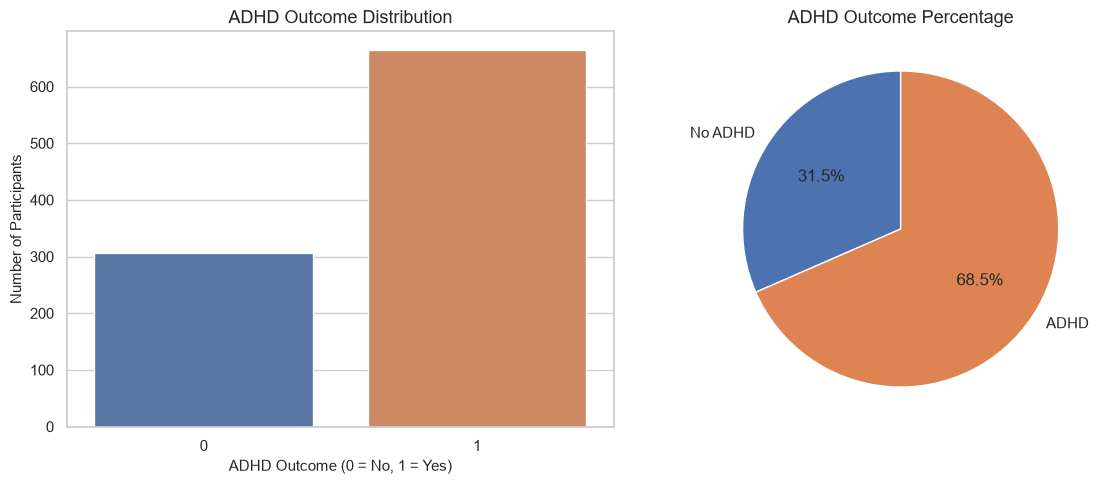

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Count plot
sns.countplot(
    data=df,
    x="ADHD_Outcome",
    hue="ADHD_Outcome",
    order=[0, 1],
    legend=False,
    ax=axes[0]
)

axes[0].set_title("ADHD Outcome Distribution")
axes[0].set_xlabel("ADHD Outcome (0 = No, 1 = Yes)")
axes[0].set_ylabel("Number of Participants")

# Percentage plot
axes[1].pie(
    adhd_summary["Count"],
    labels=adhd_summary["Class"],
    autopct="%1.1f%%",
    startangle=90
)

axes[1].set_title("ADHD Outcome Percentage")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "01_adhd_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 3.2 Distribution of Sex

Analyze the distribution of male and female participants.

This helps determine whether both classes are adequately represented and whether the target variable exhibits class imbalance.


In [6]:
# Calculate sex distribution

sex_counts = df["Sex_F"].value_counts().sort_index()

sex_summary = pd.DataFrame({
    "Class": ["Male", "Female"],
    "Count": [
        sex_counts.get(0, 0),
        sex_counts.get(1, 0)
    ]
})

sex_summary["Percentage"] = (
    sex_summary["Count"] / len(df) * 100
)

display(sex_summary)

,Class,Count,Percentage
0,Male,637,65.670
1,Female,333,34.330


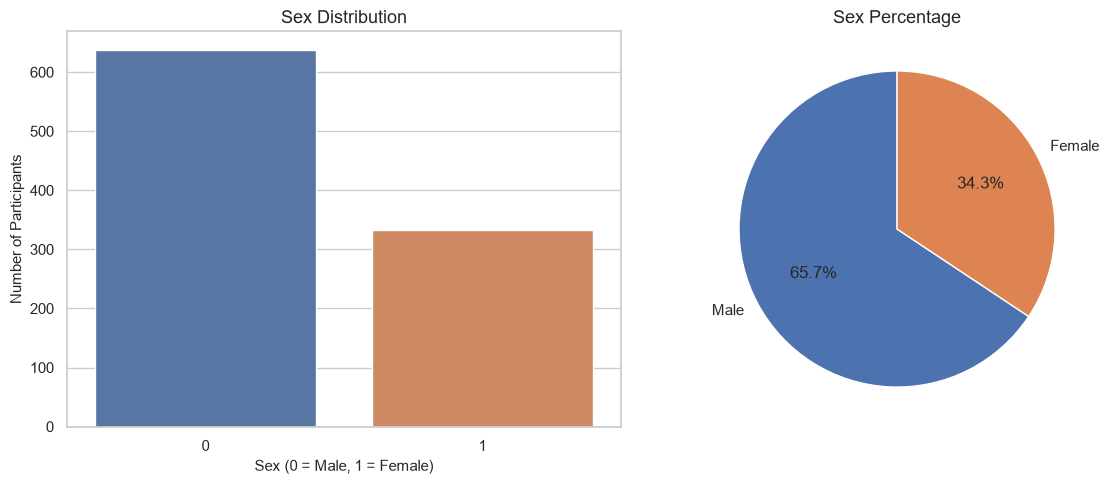

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(
    data=df,
    x="Sex_F",
    hue="Sex_F",
    order=[0, 1],
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Sex Distribution")
axes[0].set_xlabel("Sex (0 = Male, 1 = Female)")
axes[0].set_ylabel("Number of Participants")

axes[1].pie(
    sex_summary["Count"],
    labels=sex_summary["Class"],
    autopct="%1.1f%%",
    startangle=90
)

axes[1].set_title("Sex Percentage")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "02_sex_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 3.3 Joint Distribution of ADHD Outcome and Sex

Analyze the combined distribution of ADHD diagnosis and sex.

Since both target variables are binary, four possible combinations exist:

1. No ADHD, Male
2. No ADHD, Female
3. ADHD, Male
4. ADHD, Female

This analysis is particularly important because the project evaluation assigns additional importance to the ADHD-positive female subgroup.

The joint distribution will help identify whether certain combinations are underrepresented.


In [8]:
# Create a temporary combined target variable

df["Target_Group"] = (
    df["ADHD_Outcome"] * 2 + df["Sex_F"]
)

# Define readable labels

group_labels = {
    0: "No ADHD - Male",
    1: "No ADHD - Female",
    2: "ADHD - Male",
    3: "ADHD - Female"
}

df["Target_Group_Label"] = (
    df["Target_Group"].map(group_labels)
)

# Calculate distribution

joint_distribution = (
    df["Target_Group_Label"]
    .value_counts()
    .reindex(group_labels.values())
)

joint_summary = pd.DataFrame({
    "Participants": joint_distribution,
    "Percentage": (
        joint_distribution / len(df) * 100
    )
})

display(joint_summary)

,Participants,Percentage
Target_Group_Label,,
No ADHD - Male,173,17.835
No ADHD - Female,133,13.711
ADHD - Male,464,47.835
ADHD - Female,200,20.619


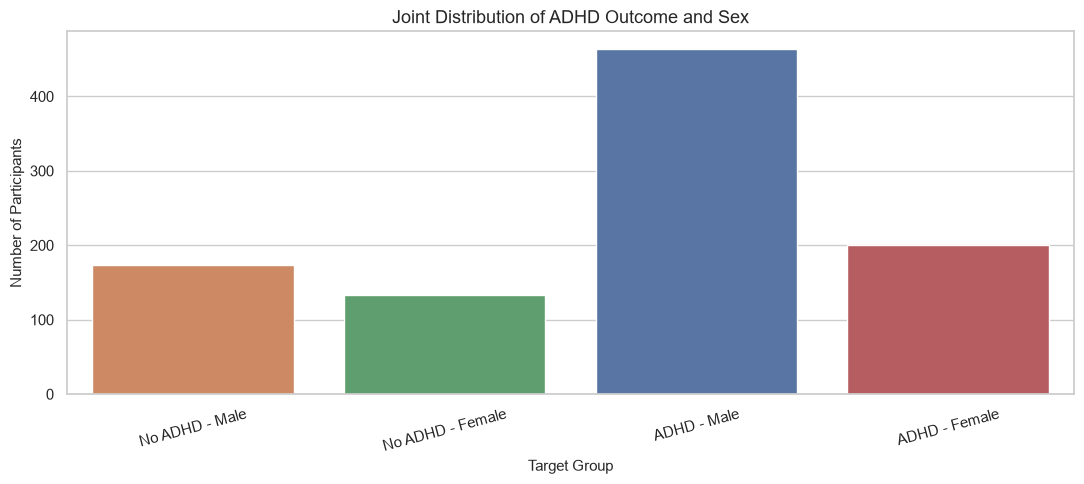

In [9]:
plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    x="Target_Group_Label",
    hue="Target_Group_Label",
    order=list(group_labels.values()),
    legend=False
)

plt.title("Joint Distribution of ADHD Outcome and Sex")
plt.xlabel("Target Group")
plt.ylabel("Number of Participants")
plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "03_joint_target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
# Cross-tabulate ADHD and Sex

target_crosstab = pd.crosstab(
    df["ADHD_Outcome"],
    df["Sex_F"],
    margins=True
)

target_crosstab.index = [
    "No ADHD",
    "ADHD",
    "Total"
]

target_crosstab.columns = [
    "Male",
    "Female",
    "Total"
]

display(target_crosstab)

,Male,Female,Total
No ADHD,173,133,306
ADHD,464,200,664
Total,637,333,970


In [11]:
target_percentage = pd.crosstab(
    df["ADHD_Outcome"],
    df["Sex_F"],
    normalize="index"
) * 100

display(target_percentage.round(2))

Sex_F,0,1
ADHD_Outcome,,
0,56.540,43.460
1,69.880,30.120



### 3.4 Class Imbalance Analysis

Examine the relative representation of the four combined target groups.

Class imbalance occurs when some classes contain substantially more observations than others.

This is relevant because a model trained on imbalanced data may favour majority groups and perform poorly on underrepresented groups.

The analysis will help guide subsequent decisions regarding class weighting, sampling strategies and threshold optimization.


In [13]:
# Calculate imbalance ratio for the combined target groups

group_counts = (
    df["Target_Group"]
    .value_counts()
    .sort_index()
)

imbalance_ratio = (
    group_counts.max() / group_counts.min()
)

print("Combined Target Group Counts")
print(group_counts)

print("\nLargest / Smallest Group Ratio:",
      round(imbalance_ratio, 2))

print("\nSmallest Group:",
      group_counts.idxmin())

print("Largest Group:",
      group_counts.idxmax())

Combined Target Group Counts
Target_Group
0    173
1    133
2    464
3    200
Name: count, dtype: int64

Largest / Smallest Group Ratio: 3.49

Smallest Group: 1
Largest Group: 2



## 3.5 Observations and Findings

### ADHD Outcome Distribution

- No ADHD: 306 participants (31.5%).
- ADHD: 664 participants (68.5%).
- The dataset exhibits class imbalance, with approximately 2.17 times as many ADHD-positive participants.

### Sex Distribution

- Male: 637 participants (65.7%).
- Female: 333 participants (34.3%).
- Male participants are more represented, with a male-to-female ratio of approximately 1.91:1.

### Joint Target Distribution

- No ADHD - Male: 173 participants (17.84%).
- No ADHD - Female: 133 participants (13.71%).
- ADHD - Male: 464 participants (47.84%).
- ADHD - Female: 200 participants (20.62%).

The ADHD-positive male group is the largest, while the No ADHD female group is the smallest.

The combined target groups have an imbalance ratio of approximately 3.49:1.

### Additional Observation

Among ADHD-positive participants, 30.12% are female, compared with 43.46% among participants without ADHD.

This represents an observed difference in the development dataset and does not establish causation.

### Implications for Modelling

1. Accuracy alone may be misleading due to class imbalance.
2. Both target variables must be evaluated independently.
3. The four combined target groups should be monitored during model evaluation.
4. Class weighting and threshold optimization will be investigated during model development.
5. Oversampling techniques will only be considered after establishing baseline performance.

### Conclusion

The development dataset exhibits imbalance in both target variables and their joint distribution. This makes appropriate evaluation metrics and careful model selection particularly important.



## 4. Missing Value Analysis

Missing values can affect the quality of the training data and the performance of machine learning models.

This section investigates missingness across the predictor variables to understand its extent and distribution.

The analysis includes:

- Missing-value counts and percentages per feature.
- Overall missingness across the dataset.
- Identification of features with the highest missingness.
- Missingness across different feature groups.
- Participant-level missingness patterns.

No missing-value imputation or deletion is performed during this stage.


In [14]:
# Identify target and identifier columns

target_cols = ["ADHD_Outcome", "Sex_F"]

identifier_cols = ["participant_id"]

# Exclude temporary target-group columns if present

helper_cols = ["Target_Group", "Target_Group_Label"]

# Extract predictor features only

feature_df = df.drop(
    columns=target_cols + identifier_cols + helper_cols,
    errors="ignore"
)

print("Predictor dataset shape:", feature_df.shape)

Predictor dataset shape: (970, 19927)


In [15]:
# Calculate missing-value statistics

missing_summary = pd.DataFrame({
    "Missing_Count": feature_df.isnull().sum(),
    "Missing_Percentage": (
        feature_df.isnull().mean() * 100
    )
})

missing_summary = (
    missing_summary
    .sort_values(
        by="Missing_Percentage",
        ascending=False
    )
)

# Retain only features containing missing values

missing_features = missing_summary[
    missing_summary["Missing_Count"] > 0
]

print("Total predictor features:", feature_df.shape[1])

print("Features with missing values:",
      len(missing_features))

print("Features without missing values:",
      feature_df.shape[1] - len(missing_features))

display(missing_features.head(30))

Total predictor features: 19927
Features with missing values: 25
Features without missing values: 19902


,Missing_Count,Missing_Percentage
MRI_Track_Age_at_Scan,286,29.485
Barratt_Barratt_P2_Occ,185,19.072
Barratt_Barratt_P2_Edu,162,16.701
PreInt_Demos_Fam_Child_Race,44,4.536
PreInt_Demos_Fam_Child_Ethnicity,33,3.402
Barratt_Barratt_P1_Occ,27,2.784
ColorVision_CV_Score,16,1.649
Barratt_Barratt_P1_Edu,13,1.340
EHQ_EHQ_Total,11,1.134
APQ_P_APQ_P_CP,11,1.134


In [16]:
total_values = feature_df.size

total_missing = feature_df.isnull().sum().sum()

overall_missing_percentage = (
    total_missing / total_values * 100
)

print("Total predictor values:", total_values)

print("Total missing values:", total_missing)

print(
    "Overall missing percentage:",
    round(overall_missing_percentage, 3), "%"
)

Total predictor values: 19329190
Total missing values: 908
Overall missing percentage: 0.005 %


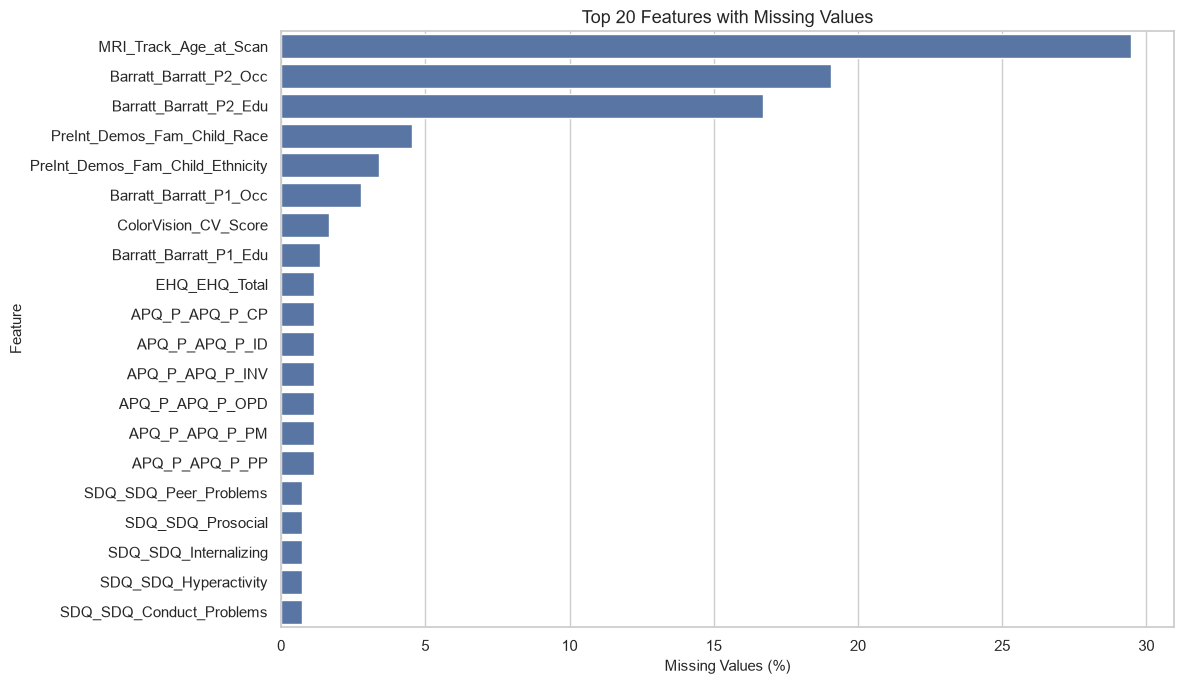

In [17]:
top_missing = missing_features.head(20).reset_index()

top_missing = top_missing.rename(
    columns={"index": "Feature"}
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_missing,
    x="Missing_Percentage",
    y="Feature"
)

plt.title("Top 20 Features with Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "04_top_missing_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
# Count missing features for each participant

participant_missing = pd.DataFrame({
    "participant_id": df["participant_id"],
    "Missing_Features": feature_df.isnull().sum(axis=1)
})

participant_missing["Missing_Percentage"] = (
    participant_missing["Missing_Features"]
    / feature_df.shape[1] * 100
)

display(
    participant_missing.sort_values(
        "Missing_Features",
        ascending=False
    ).head(20)
)

,participant_id,Missing_Features,Missing_Percentage
573,7DOnnFs86L8o,11,0.055
344,MMH1uM7wltAr,11,0.055
789,16aihxrHTH3I,11,0.055
272,WHWymJu6zNZi,10,0.050
128,U3FzDZTOsMlD,9,0.045
318,A1AXFSUEtLFQ,9,0.045
209,2Mjpn48uEjoY,9,0.045
864,emH1j2pf9MZk,9,0.045
930,eC2397lXg3Bm,9,0.045
914,epGIlkmYMthb,7,0.035


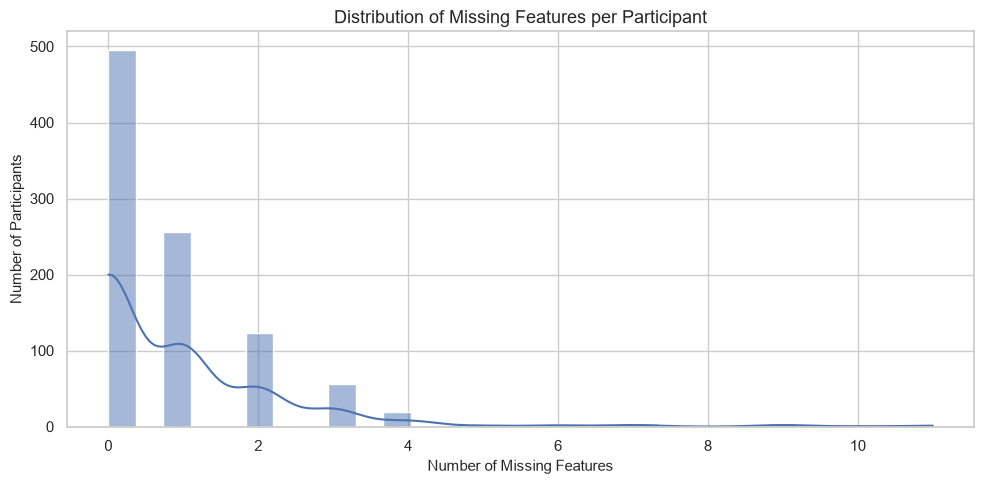

In [19]:
plt.figure(figsize=(10, 5))

sns.histplot(
    participant_missing["Missing_Features"],
    bins=30,
    kde=True
)

plt.title("Distribution of Missing Features per Participant")
plt.xlabel("Number of Missing Features")
plt.ylabel("Number of Participants")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "05_participant_missingness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# Identify feature groups using their column names

connectome_cols = [
    col for col in feature_df.columns
    if "throw_" in col
]

categorical_cols = [
    col for col in feature_df.columns
    if col.startswith((
        "Basic_Demos_",
        "PreInt_Demos_",
        "Barratt_"
    ))
    or col == "MRI_Track_Scan_Location"
]

quantitative_cols = [
    col for col in feature_df.columns
    if col.startswith((
        "EHQ_",
        "ColorVision_",
        "APQ_",
        "SDQ_"
    ))
    or col == "MRI_Track_Age_at_Scan"
]

feature_groups = {
    "Categorical Metadata": categorical_cols,
    "Quantitative Metadata": quantitative_cols,
    "Functional Connectome": connectome_cols
}

# Summarize missingness

group_missingness = []

for group_name, columns in feature_groups.items():

    group_data = feature_df[columns]

    group_missingness.append({
        "Feature_Group": group_name,
        "Total_Features": len(columns),
        "Missing_Values": group_data.isnull().sum().sum(),
        "Missing_Percentage": (
            group_data.isnull().sum().sum()
            / group_data.size * 100
            if group_data.size > 0 else 0
        )
    })

group_missingness = pd.DataFrame(group_missingness)

display(group_missingness)

,Feature_Group,Total_Features,Missing_Values,Missing_Percentage
0,Categorical Metadata,9,466,5.338
1,Quantitative Metadata,18,442,2.532
2,Functional Connectome,19900,0,0.000



### 4.6 Missingness Pattern Analysis

Investigate whether missing values in different features occur independently or are associated with one another.

Particular attention is given to Parent 2 education and occupation, as well as questionnaire-based features.

Understanding shared missingness patterns may provide insights into the underlying data collection process and help determine appropriate imputation strategies.


In [21]:
# Identify missingness indicators for selected features

selected_features = [
    "MRI_Track_Age_at_Scan",
    "Barratt_Barratt_P2_Edu",
    "Barratt_Barratt_P2_Occ",
    "Barratt_Barratt_P1_Edu",
    "Barratt_Barratt_P1_Occ"
]

missing_indicators = (
    df[selected_features]
    .isnull()
    .astype(int)
)

missing_indicators.columns = [
    col + "_Missing"
    for col in missing_indicators.columns
]

display(
    missing_indicators.value_counts(
        sort=False
    ).head(20)
)

MRI_Track_Age_at_Scan_Missing  Barratt_Barratt_P2_Edu_Missing  Barratt_Barratt_P2_Occ_Missing  Barratt_Barratt_P1_Edu_Missing  Barratt_Barratt_P1_Occ_Missing
0                              0                               0                               0                               0                                 546
                               1                               1                               0                               0                                  94
1                              0                               0                               0                               0                                 222
0                              0                               1                               0                               0                                  18
1                              1                               1                               0                               0                                  43
0                

In [22]:
p2_edu_missing = df["Barratt_Barratt_P2_Edu"].isna()
p2_occ_missing = df["Barratt_Barratt_P2_Occ"].isna()

print("Parent 2 Education Missing:", p2_edu_missing.sum())
print("Parent 2 Occupation Missing:", p2_occ_missing.sum())

print(
    "Both Missing:",
    (p2_edu_missing & p2_occ_missing).sum()
)

print(
    "Only Education Missing:",
    (p2_edu_missing & ~p2_occ_missing).sum()
)

print(
    "Only Occupation Missing:",
    (~p2_edu_missing & p2_occ_missing).sum()
)

Parent 2 Education Missing: 162
Parent 2 Occupation Missing: 185
Both Missing: 151
Only Education Missing: 11
Only Occupation Missing: 34


In [23]:
apq_cols = [
    col for col in df.columns
    if col.startswith("APQ_")
]

sdq_cols = [
    col for col in df.columns
    if col.startswith("SDQ_")
]

# Count participants with at least one missing APQ feature
apq_missing = df[apq_cols].isnull().any(axis=1)

# Count participants with at least one missing SDQ feature
sdq_missing = df[sdq_cols].isnull().any(axis=1)

print("Participants with missing APQ:", apq_missing.sum())
print("Participants with missing SDQ:", sdq_missing.sum())

print(
    "Participants missing both:",
    (apq_missing & sdq_missing).sum()
)

print(
    "Participants missing either:",
    (apq_missing | sdq_missing).sum()
)

Participants with missing APQ: 11
Participants with missing SDQ: 7
Participants missing both: 0
Participants missing either: 18


In [24]:
# Investigate missingness against both targets

features_to_check = [
    "MRI_Track_Age_at_Scan",
    "Barratt_Barratt_P2_Edu",
    "Barratt_Barratt_P2_Occ",
    "EHQ_EHQ_Total",
    "ColorVision_CV_Score"
]

missingness_target_analysis = []

for feature in features_to_check:

    missing_flag = df[feature].isna()

    for target in ["ADHD_Outcome", "Sex_F"]:

        temp = pd.DataFrame({
            "Missing": missing_flag,
            "Target": df[target]
        })

        rates = temp.groupby("Target")["Missing"].mean() * 100

        missingness_target_analysis.append({
            "Feature": feature,
            "Target": target,
            "Class_0_Missing_%": rates.get(0, np.nan),
            "Class_1_Missing_%": rates.get(1, np.nan)
        })

missingness_target_analysis = pd.DataFrame(
    missingness_target_analysis
)

display(missingness_target_analysis.round(2))

,Feature,Target,Class_0_Missing_%,Class_1_Missing_%
0,MRI_Track_Age_at_Scan,ADHD_Outcome,30.070,29.220
1,MRI_Track_Age_at_Scan,Sex_F,29.510,29.430
2,Barratt_Barratt_P2_Edu,ADHD_Outcome,14.710,17.620
3,Barratt_Barratt_P2_Edu,Sex_F,16.170,17.720
4,Barratt_Barratt_P2_Occ,ADHD_Outcome,16.010,20.480
5,Barratt_Barratt_P2_Occ,Sex_F,18.520,20.120
6,EHQ_EHQ_Total,ADHD_Outcome,0.330,1.510
7,EHQ_EHQ_Total,Sex_F,1.100,1.200
8,ColorVision_CV_Score,ADHD_Outcome,2.290,1.360
9,ColorVision_CV_Score,Sex_F,1.410,2.100



### 4.7 Missingness Pattern Analysis

#### Parent 2 Information

Parent 2 education and occupation exhibit substantial overlap in missingness.

- Both missing: 151 participants.
- Only education missing: 11 participants.
- Only occupation missing: 34 participants.

Approximately 93.21% of participants with missing Parent 2 education also have missing occupation information.

This suggests a shared missingness pattern, potentially associated with unavailable parental information.

#### Questionnaire Missingness

- APQ missingness affects 11 participants.
- SDQ missingness affects 7 participants.
- No participants have missing values in both questionnaire groups.

The missingness patterns across these two questionnaire groups appear separate.

#### Missingness and Target Variables

MRI age missingness is relatively similar across ADHD and sex classes.

Parent 2 education and occupation show somewhat higher missingness in ADHD-positive participants.

These differences are descriptive and require further statistical investigation before drawing conclusions.

#### Preprocessing Implications

1. Retain participants rather than deleting entire rows due to limited missing predictor values.
2. Investigate Parent 2 education and occupation jointly.
3. Compare appropriate categorical and numerical imputation methods.
4. Consider missingness indicators for selected features.
5. Fit all imputation transformations within cross-validation training folds to prevent data leakage.

### Conclusion

Missingness is concentrated in demographic and quantitative metadata rather than functional connectome features.

The observed patterns suggest that missing values should be handled at the feature level, with particular attention to Parent 2 information and MRI age at scan.



## 5. Demographic and Categorical Feature Analysis

This section explores the demographic and categorical metadata associated with the participants.

The analysis examines:

- Enrollment year distribution.
- Study site distribution.
- Child ethnicity and race.
- MRI scan location.
- Parental education and occupation.

Although these variables are represented using numerical codes, many of them represent categorical information rather than continuous numerical measurements.

The analysis focuses on their distributions, category frequencies, missingness and relationships with the two target variables.


In [25]:
# Define categorical metadata features

categorical_features = [
    "Basic_Demos_Enroll_Year",
    "Basic_Demos_Study_Site",
    "PreInt_Demos_Fam_Child_Ethnicity",
    "PreInt_Demos_Fam_Child_Race",
    "MRI_Track_Scan_Location",
    "Barratt_Barratt_P1_Edu",
    "Barratt_Barratt_P1_Occ",
    "Barratt_Barratt_P2_Edu",
    "Barratt_Barratt_P2_Occ"
]

# Verify all expected columns exist

missing_columns = [
    col for col in categorical_features
    if col not in df.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

print("Categorical features identified:",
      len(categorical_features))

Categorical features identified: 9


In [26]:
for feature in categorical_features:

    print("\n" + "=" * 70)
    print(feature)
    print("=" * 70)

    print("Unique categories:",
          df[feature].nunique(dropna=True))

    print("\nCategory frequencies:")

    display(
        df[feature]
        .value_counts(dropna=False)
        .sort_index()
        .to_frame("Count")
    )


Basic_Demos_Enroll_Year
Unique categories: 6

Category frequencies:


,Count
Basic_Demos_Enroll_Year,
2015,28
2016,151
2017,203
2018,336
2019,249
2020,3



Basic_Demos_Study_Site
Unique categories: 4

Category frequencies:


,Count
Basic_Demos_Study_Site,
1,517
2,8
3,346
4,99



PreInt_Demos_Fam_Child_Ethnicity
Unique categories: 4

Category frequencies:


,Count
PreInt_Demos_Fam_Child_Ethnicity,
0.000,629
1.000,235
2.000,58
3.000,15
NaN,33


... (8 outputs left out)


Barratt_Barratt_P2_Edu
Unique categories: 7

Category frequencies:


,Count
Barratt_Barratt_P2_Edu,
3.000,4
6.000,12
9.000,37
12.000,117
15.000,124
18.000,255
21.000,259
NaN,162



Barratt_Barratt_P2_Occ
Unique categories: 10

Category frequencies:


,Count
Barratt_Barratt_P2_Occ,
0.000,44
5.000,30
10.000,26
15.000,66
20.000,33
25.000,19
30.000,120
35.000,155
40.000,86



### 5.3 Enrollment Year Distribution

Examine the distribution of participants across enrollment years.

Enrollment year is stored as an integer but represents a temporal variable.

The analysis will help identify differences in participant counts across years and provide context for deciding whether to treat this feature as numerical or categorical during preprocessing.


In [27]:
year_counts = (
    df["Basic_Demos_Enroll_Year"]
    .value_counts(dropna=False)
    .sort_index()
)

display(year_counts.to_frame("Participants"))

,Participants
Basic_Demos_Enroll_Year,
2015,28
2016,151
2017,203
2018,336
2019,249
2020,3


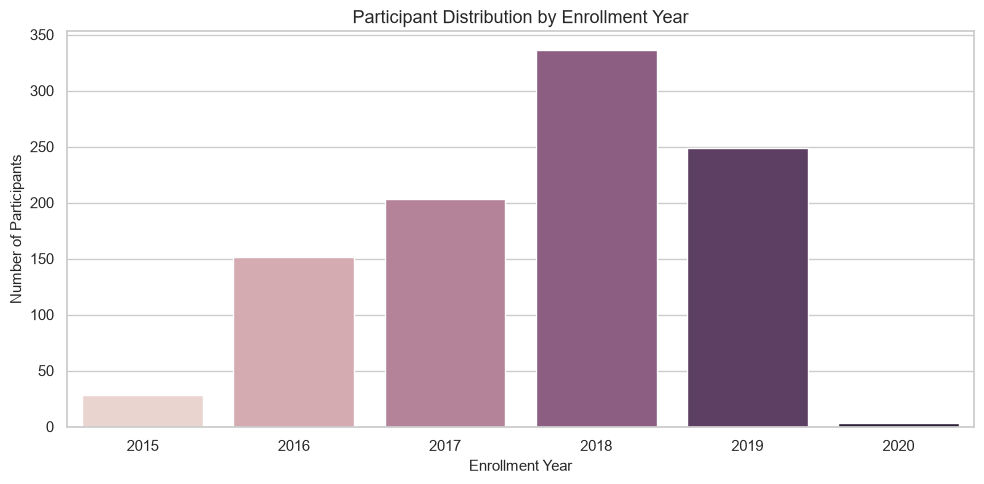

In [28]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Basic_Demos_Enroll_Year",
    order=sorted(
        df["Basic_Demos_Enroll_Year"].dropna().unique()
    ),
    hue="Basic_Demos_Enroll_Year",
    legend=False
)

plt.title("Participant Distribution by Enrollment Year")
plt.xlabel("Enrollment Year")
plt.ylabel("Number of Participants")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "06_enrollment_year_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 5.4 Study Site Distribution

Analyze the distribution of participants across different study sites.

This helps identify whether the dataset is dominated by a particular site.

Differences between study sites may reflect variations in data collection environments, participant recruitment or acquisition procedures.

Such differences should be investigated before deciding whether study site provides useful predictive information.


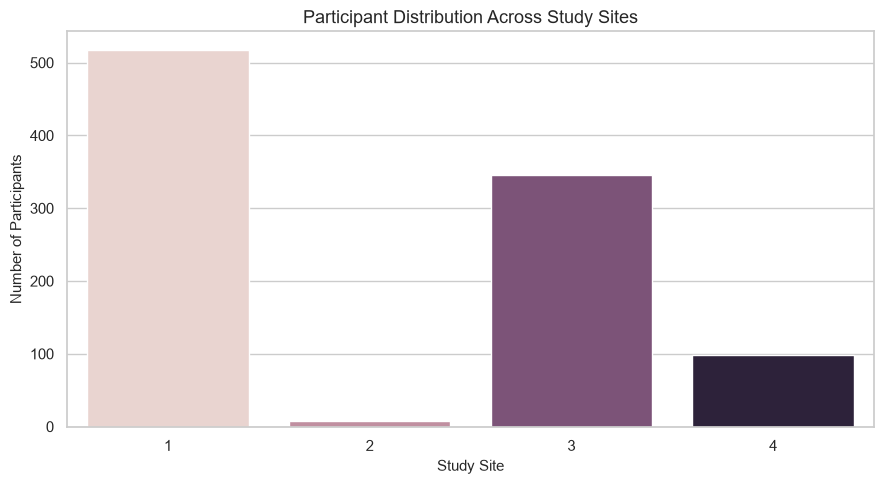

In [29]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Basic_Demos_Study_Site",
    hue="Basic_Demos_Study_Site",
    legend=False
)

plt.title("Participant Distribution Across Study Sites")
plt.xlabel("Study Site")
plt.ylabel("Number of Participants")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "07_study_site_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 5.5 Child Ethnicity and Race Distribution

Explore the distribution of ethnicity and race categories among participants.

These variables are represented by numerical category codes.

The analysis examines the frequency of each category and identifies rare or underrepresented categories.

The numerical codes are treated as category identifiers rather than continuous measurements.


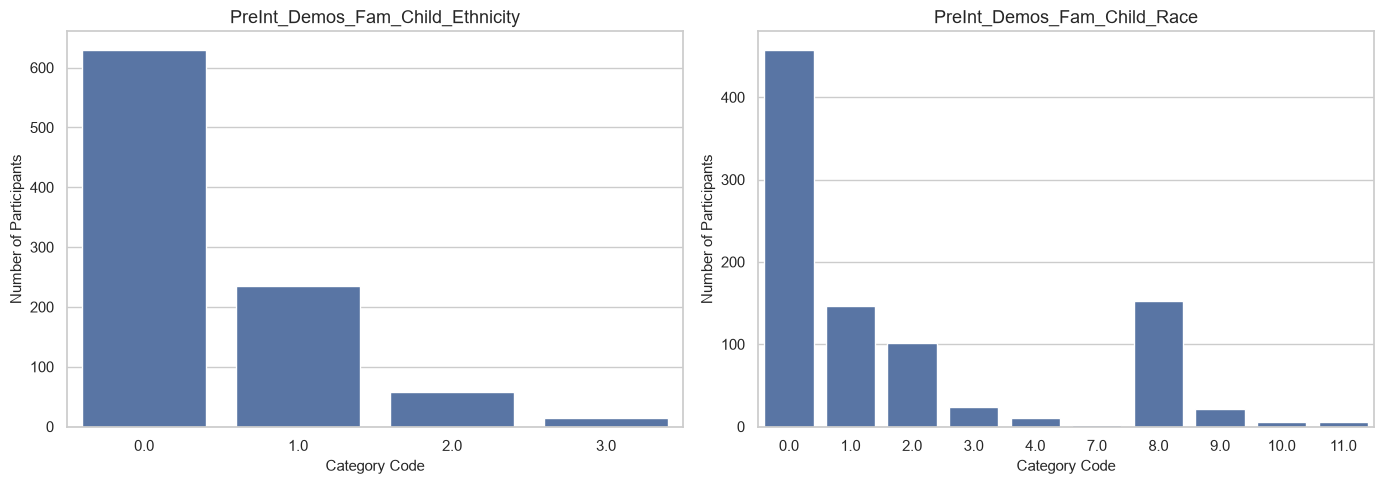

In [30]:
ethnicity_race_features = [
    "PreInt_Demos_Fam_Child_Ethnicity",
    "PreInt_Demos_Fam_Child_Race"
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, feature in zip(axes, ethnicity_race_features):

    counts = (
        df[feature]
        .value_counts()
        .sort_index()
    )

    sns.barplot(
        x=counts.index.astype(str),
        y=counts.values,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("Category Code")
    ax.set_ylabel("Number of Participants")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "08_ethnicity_race_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 5.6 MRI Scan Location Distribution

Analyze the distribution of participants across MRI scan locations.

This feature may capture differences in acquisition environments or scanning locations.

Its relationship with ADHD and sex will be examined to identify possible associations that may influence model predictions.


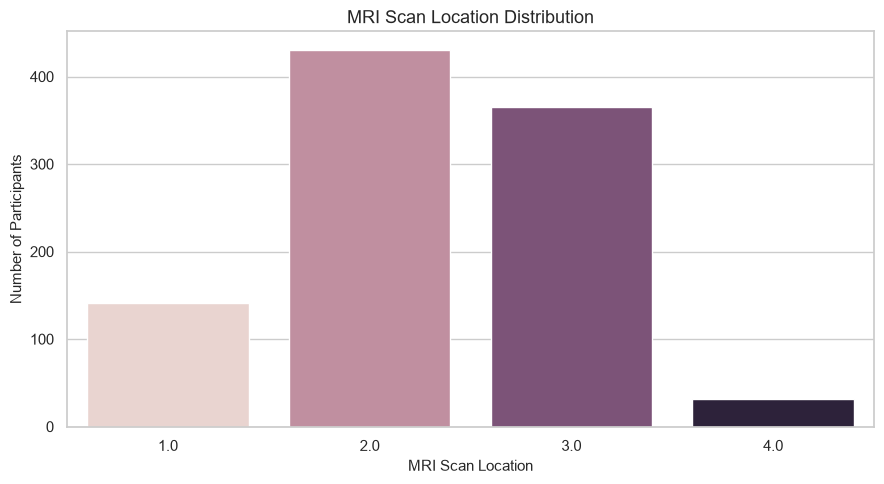

In [31]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="MRI_Track_Scan_Location",
    hue="MRI_Track_Scan_Location",
    legend=False
)

plt.title("MRI Scan Location Distribution")
plt.xlabel("MRI Scan Location")
plt.ylabel("Number of Participants")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "09_mri_scan_location.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 5.7 Parental Education and Occupation

Examine parental education and occupation categories using the Barratt Simplified Measure of Social Status features.

The analysis includes information for both parents.

The objective is to understand category distributions, identify rare categories and investigate the extent of missing information.

The feature codes will be interpreted using the data dictionary rather than assuming that their numerical values represent continuous measurements.


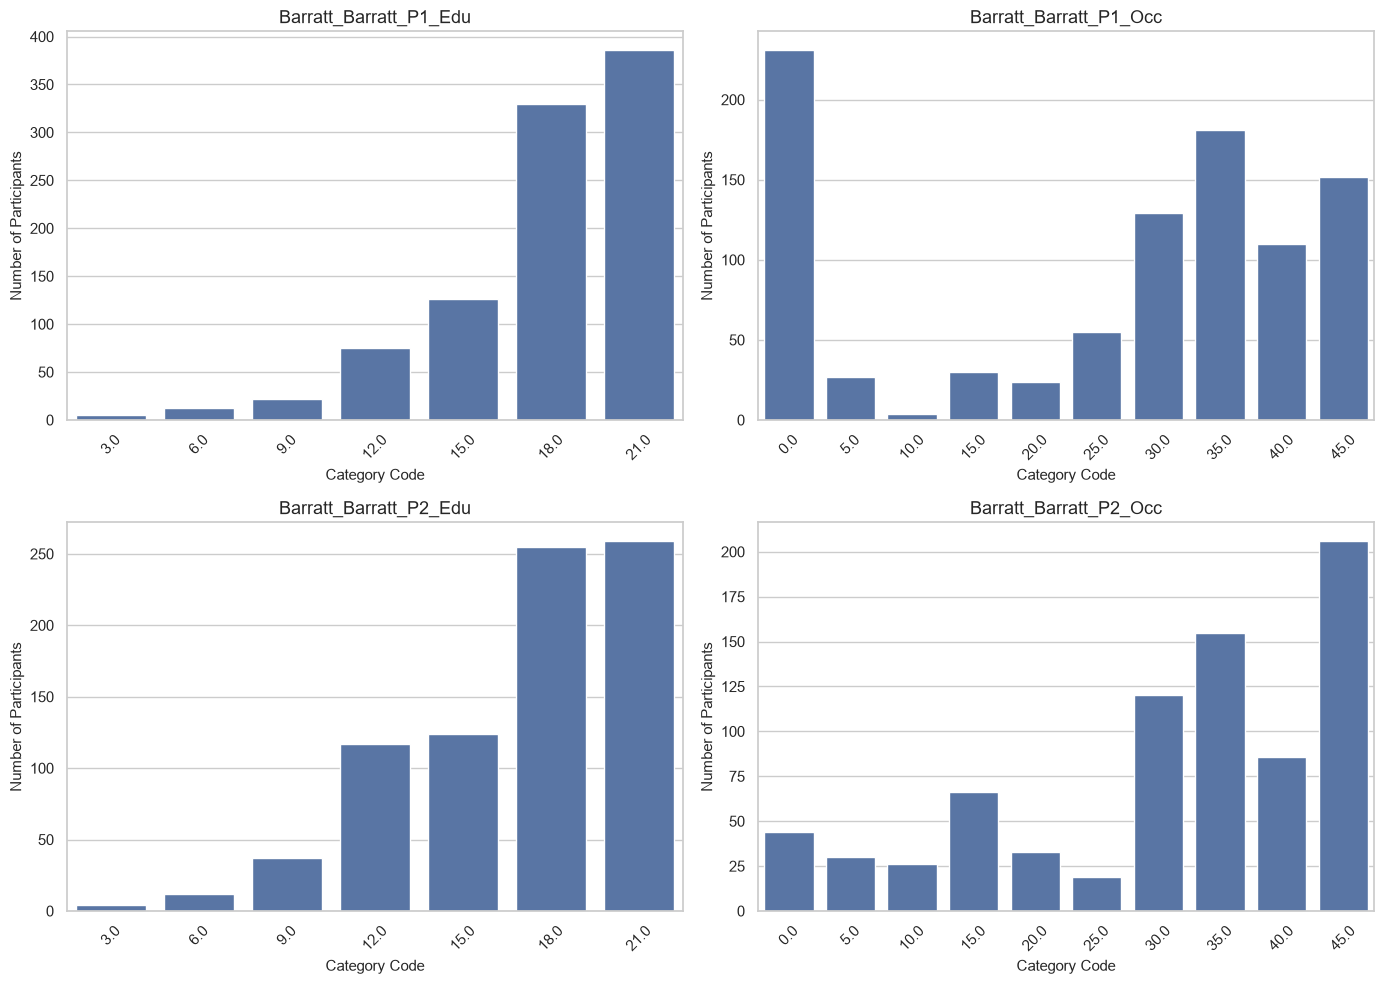

In [32]:
parent_features = [
    "Barratt_Barratt_P1_Edu",
    "Barratt_Barratt_P1_Occ",
    "Barratt_Barratt_P2_Edu",
    "Barratt_Barratt_P2_Occ"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feature in zip(axes.flatten(), parent_features):

    counts = (
        df[feature]
        .value_counts()
        .sort_index()
    )

    sns.barplot(
        x=counts.index.astype(str),
        y=counts.values,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("Category Code")
    ax.set_ylabel("Number of Participants")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "10_parental_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 5.8 Relationship Between Categorical Features and Target Variables

Investigate the distribution of categorical features across the ADHD and sex target classes.

This analysis helps identify potential relationships between demographic characteristics and the prediction targets.

Category-wise proportions are used instead of raw counts to make comparisons between categories of different sizes easier.

The analysis is exploratory and does not establish causal relationships.


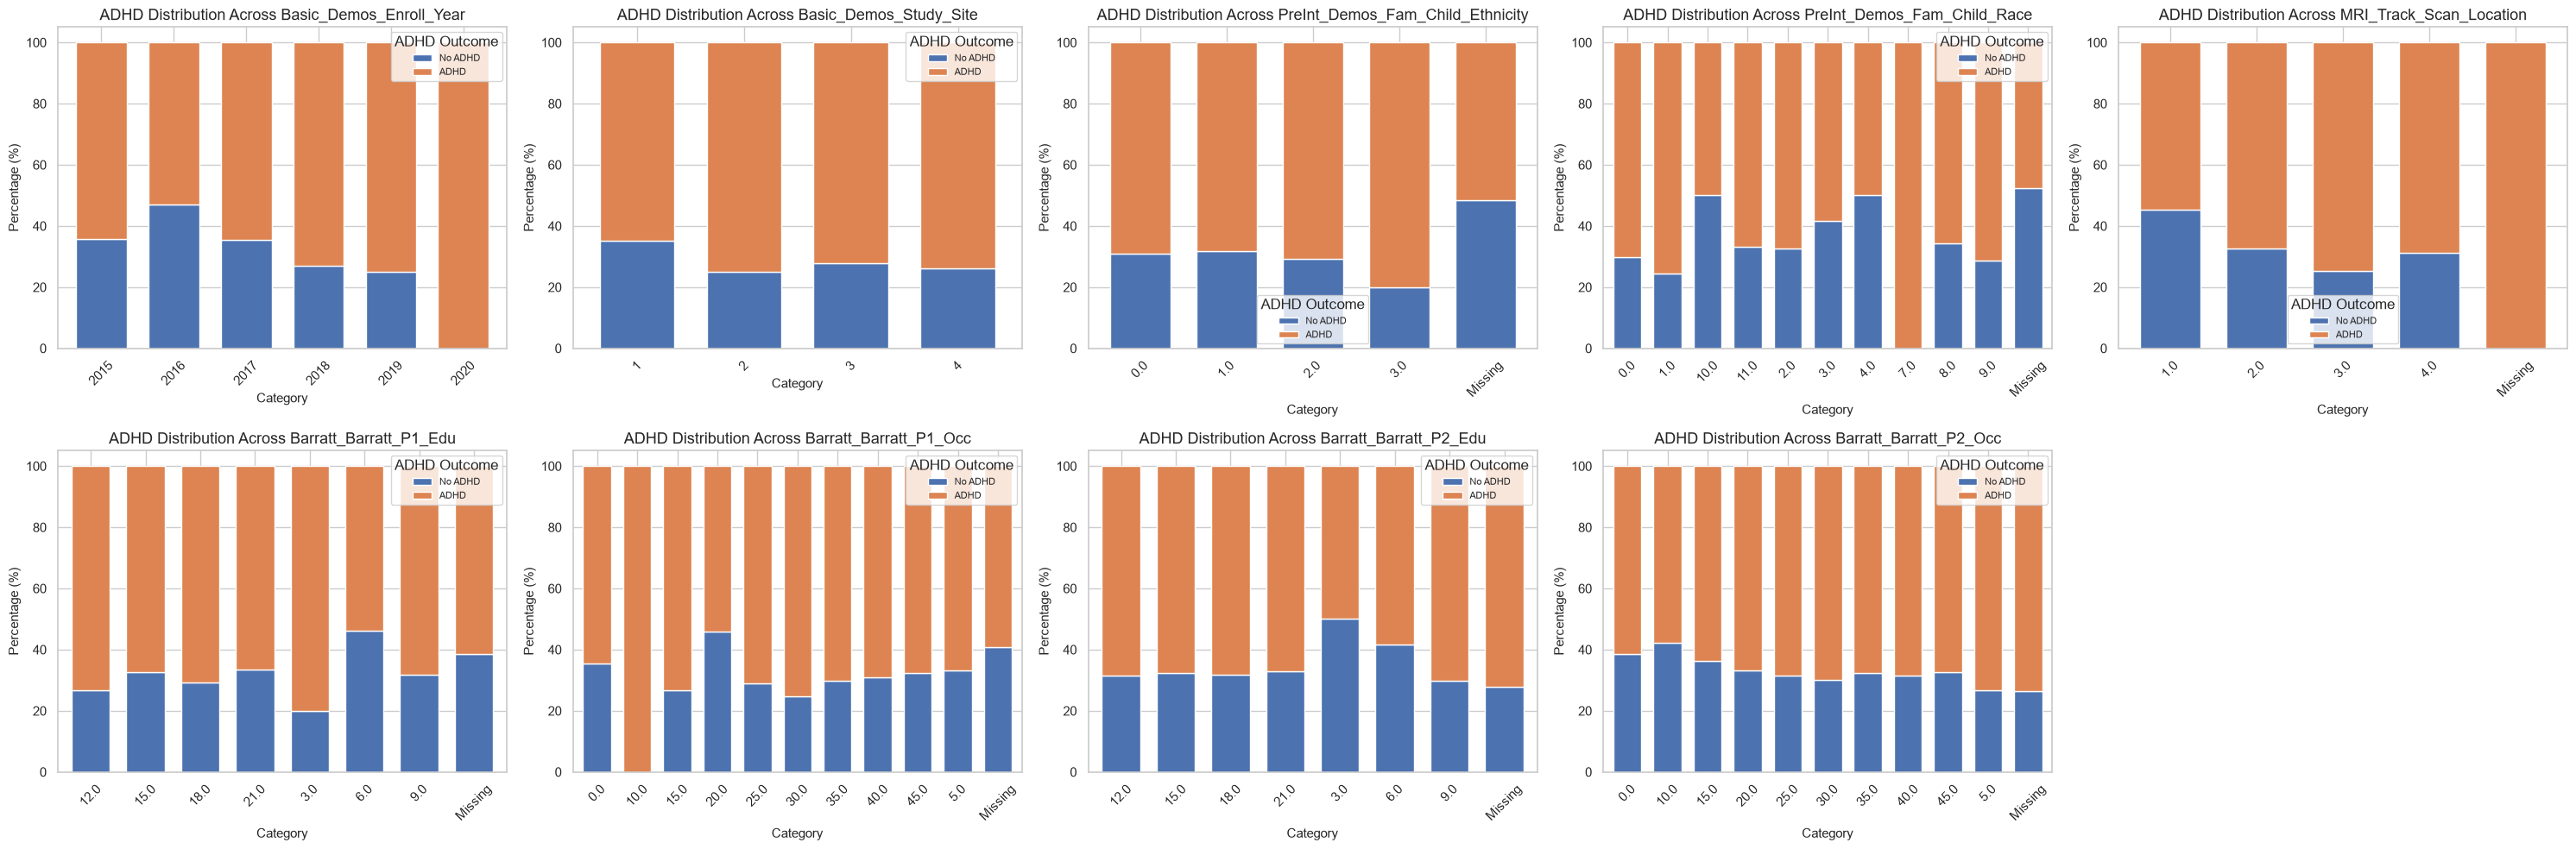

In [44]:
n_cols = 5
n_rows = 2

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(30, 5 * n_rows)
)

axes = axes.flatten()

for i, feature in enumerate(categorical_features):

    temp = df[[feature, "ADHD_Outcome"]].copy()

    # Represent missing values explicitly for visualization
    temp[feature] = (
        temp[feature].astype("string").fillna("Missing")
    )

    # Calculate within-category ADHD proportions
    proportions = pd.crosstab(
        temp[feature],
        temp["ADHD_Outcome"],
        normalize="index"
    ) * 100

    proportions.plot(
        kind="bar",
        stacked=True,
        ax=axes[i],
        width=0.7
    )

    axes[i].set_title(f"ADHD Distribution Across {feature}")
    axes[i].set_xlabel("Category")
    axes[i].set_ylabel("Percentage (%)")
    axes[i].tick_params(axis="x", rotation=45)

    axes[i].legend(
        title="ADHD Outcome",
        labels=["No ADHD", "ADHD"],
        fontsize=8
    )

# Remove unused subplot axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "adhd_categorical_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


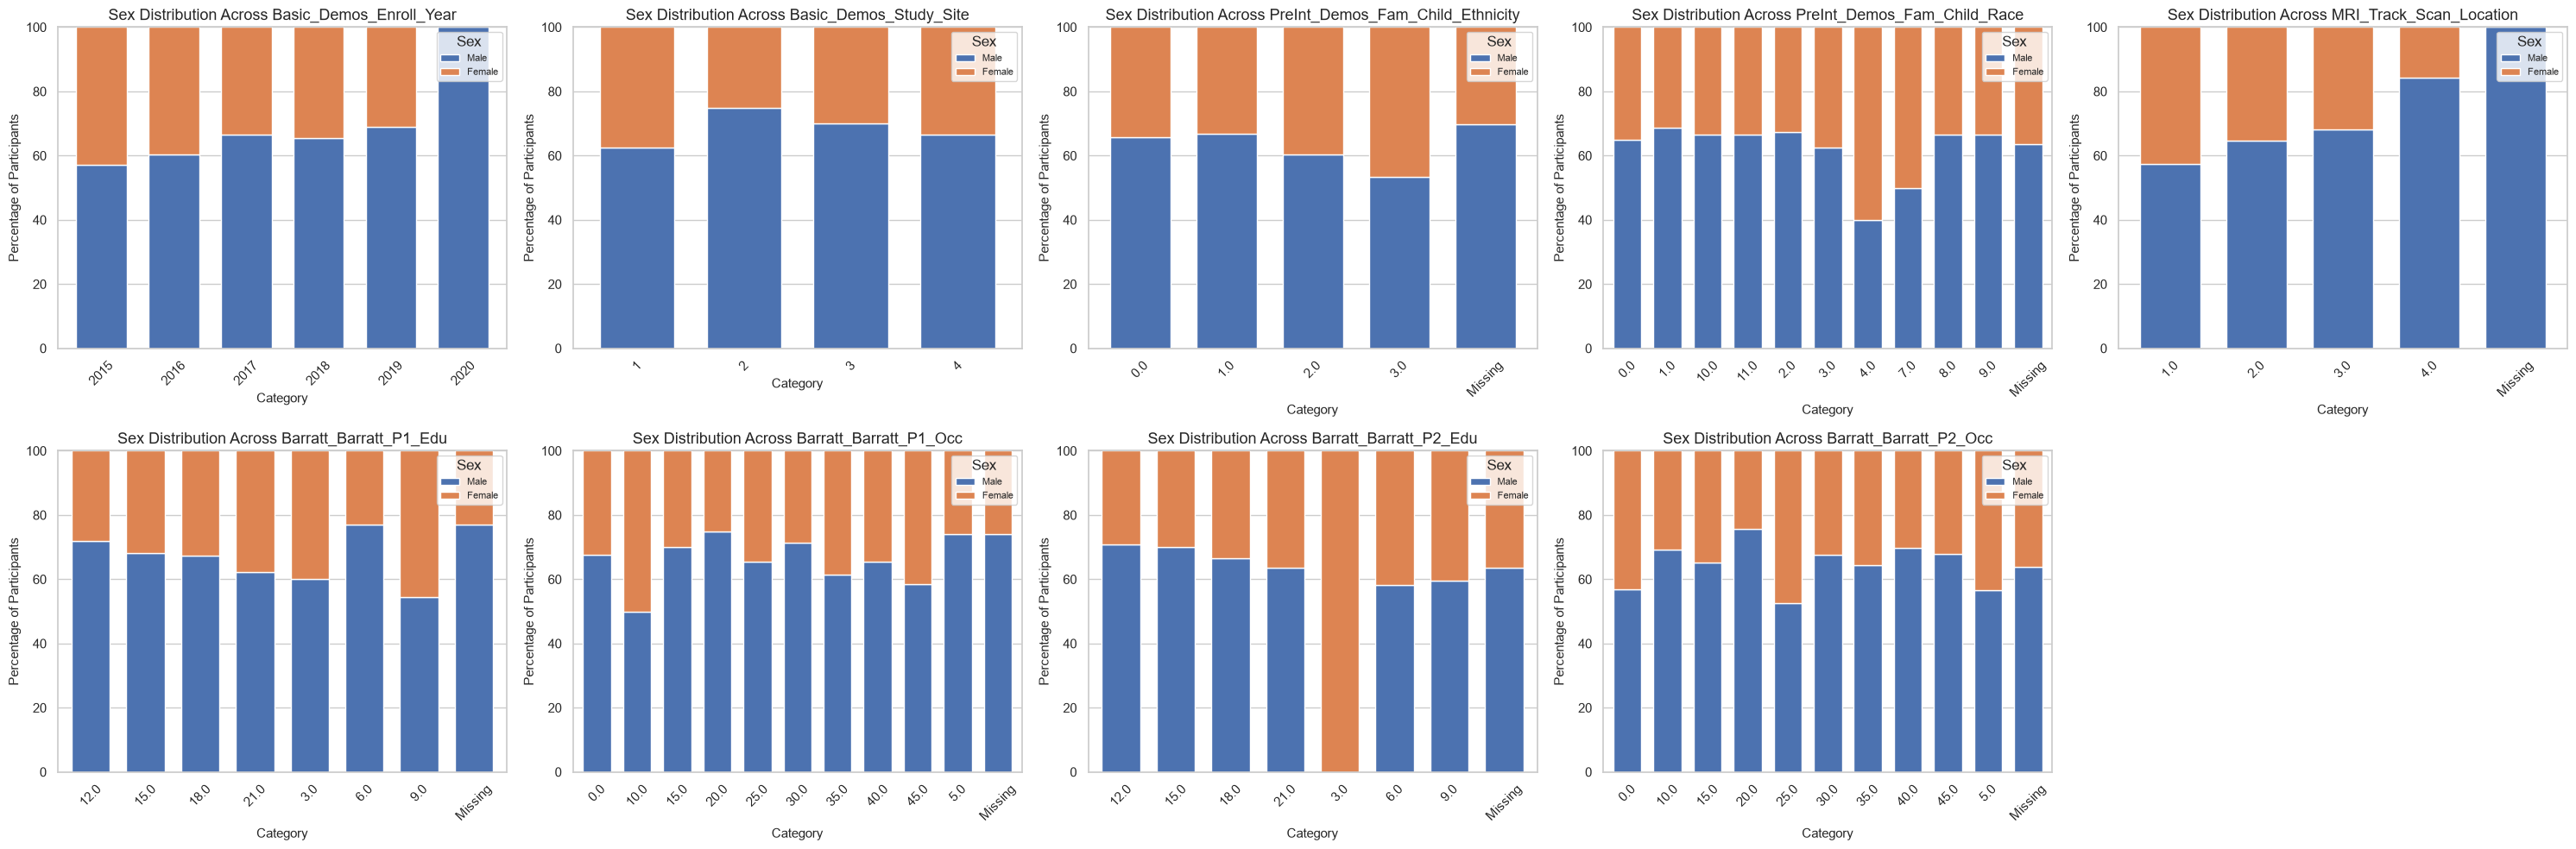

In [43]:
n_rows, n_cols = 2,5

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(30, 5 * n_rows)
)

axes = axes.flatten()

for i, feature in enumerate(categorical_features):

    temp = df[[feature, "Sex_F"]].copy()

    temp[feature] = (
        temp[feature].astype("string").fillna("Missing")
    )

    proportions = pd.crosstab(
        temp[feature],
        temp["Sex_F"],
        normalize="index"
    ) * 100

    proportions.plot(
        kind="bar",
        stacked=True,
        ax=axes[i],
        width=0.7
    )

    axes[i].set_title(f"Sex Distribution Across {feature}")
    axes[i].set_xlabel("Category")
    axes[i].set_ylabel("Percentage of Participants")
    axes[i].set_ylim(0, 100)
    axes[i].tick_params(axis="x", rotation=45)

    axes[i].legend(
        title="Sex",
        labels=["Male", "Female"],
        fontsize=8
    )

# Remove unused subplot spaces
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "sex_categorical_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [51]:
dictionary = pd.read_excel(
    DATA_DIR / "Data Dictionary.xlsx",
    sheet_name="Dictionary"
)

categorical_dictionary = dictionary[
    dictionary["Field"].isin(categorical_features)
]

display(
    categorical_dictionary[
        ["Field", "Description", "Type", "Labels"]
    ].reset_index(drop=True)
)

,Field,Description,Type,Labels
0,Basic_Demos_Enroll_Year,Year of enrollment,int,NaN
1,Basic_Demos_Study_Site,Site of phenotypic testing,categorical int,1=Staten Island \n2=MRV\n3=Midtown\n4=Harlem\n...
2,PreInt_Demos_Fam_Child_Ethnicity,Ethnicity of child,categorical int,0= Not Hispanic or Latino\n1= Hispanic or Lati...
3,PreInt_Demos_Fam_Child_Race,Race of child,categorical int,0= White/Caucasian\n1= Black/African American\...
4,MRI_Track_Scan_Location,Scan location,categorical int,1=Staten Island\n2=RUBIC\n3=CBIC\n4=CUNY
5,Barratt_Barratt_P1_Edu,Parent 1 level of education,categorical int,3=Less than 7th grade\n6=Junior high/Middle sc...
6,Barratt_Barratt_P1_Occ,Parent 1 occupation,categorical int,"0=Homemaker, stay at home parent.\n5=Day labor..."
7,Barratt_Barratt_P2_Edu,Parent 2 level of education,categorical int,3=Less than 7th grade\n6=Junior high/Middle sc...
8,Barratt_Barratt_P2_Occ,Parent 2 occupation,categorical int,"0=Homemaker, stay at home parent.\n5=Day labor..."



### 5.9 Summary and Feature Encoding Decisions

The categorical feature analysis revealed a mixture of temporal and categorical variables.

**Key findings:**

1. Enrollment year is concentrated between 2017 and 2019, with 2018 having the highest representation.
2. Study Site 1 and Site 3 account for most participants, while Site 2 is significantly underrepresented.
3. Ethnicity and race distributions are imbalanced, with several rare categories.
4. MRI scan locations 2 and 3 have the highest representation.
5. Parental education and occupation variables contain multiple coded categories and missing observations.
6. The distribution of ADHD and Sex varies across certain demographic categories, although rare categories require cautious interpretation.

**Initial preprocessing decisions:**

- Enrollment year will initially be retained as a numerical temporal feature.
- Study site, ethnicity, race and MRI scan location will be treated as nominal categorical variables.
- Parental education will initially use one-hot encoding, with ordinal encoding considered as an alternative.
- Parental occupation will initially use one-hot encoding.
- Missing categorical values will be handled during the preprocessing stage.
- Rare categories will be preserved initially rather than automatically removed or merged.

The final encoding strategy will be selected through cross-validation.



# 6. Quantitative Feature Analysis

This section explores the quantitative metadata features to understand their statistical properties and distributions.

The analysis focuses on:

1. Descriptive statistics.
2. Feature distributions and skewness.
3. Identification of potential outliers.
4. Distribution comparisons across ADHD and Sex groups.
5. Correlations between quantitative features.

The objective is to understand the numerical characteristics of the dataset and identify potential preprocessing requirements.

No imputation, scaling, outlier removal or feature transformation is performed during this stage.


In [52]:
quantitative_features = [
    "EHQ_EHQ_Total",
    "ColorVision_CV_Score",

    # APQ features
    "APQ_P_APQ_P_CP",
    "APQ_P_APQ_P_ID",
    "APQ_P_APQ_P_INV",
    "APQ_P_APQ_P_OPD",
    "APQ_P_APQ_P_PM",
    "APQ_P_APQ_P_PP",

    # SDQ features
    "SDQ_SDQ_Conduct_Problems",
    "SDQ_SDQ_Difficulties_Total",
    "SDQ_SDQ_Emotional_Problems",
    "SDQ_SDQ_Externalizing",
    "SDQ_SDQ_Generating_Impact",
    "SDQ_SDQ_Hyperactivity",
    "SDQ_SDQ_Internalizing",
    "SDQ_SDQ_Peer_Problems",
    "SDQ_SDQ_Prosocial",

    # MRI
    "MRI_Track_Age_at_Scan"
]

# Verify feature availability
missing_columns = [
    col for col in quantitative_features
    if col not in df.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

print("Quantitative features:", len(quantitative_features))

quantitative_df = df[quantitative_features].copy()

print("Quantitative dataset shape:", quantitative_df.shape)

Quantitative features: 18
Quantitative dataset shape: (970, 18)


In [53]:
descriptive_stats = (
    quantitative_df
    .describe()
    .T
)

descriptive_stats["Median"] = (
    quantitative_df.median()
)

descriptive_stats["Skewness"] = (
    quantitative_df.skew()
)

descriptive_stats["Missing_Count"] = (
    quantitative_df.isnull().sum()
)

descriptive_stats["Missing_Percentage"] = (
    quantitative_df.isnull().mean() * 100
)

display(descriptive_stats.round(3))

,count,mean,std,min,25%,50%,75%,max,Median,Skewness,Missing_Count,Missing_Percentage
EHQ_EHQ_Total,959.000,57.720,51.085,-100.000,44.470,74.470,93.340,100.000,74.470,-1.599,11,1.134
ColorVision_CV_Score,954.000,13.409,2.149,0.000,14.000,14.000,14.000,14.000,14.000,-4.920,16,1.649
APQ_P_APQ_P_CP,959.000,3.828,1.332,2.000,3.000,3.000,4.000,12.000,3.000,1.870,11,1.134
APQ_P_APQ_P_ID,959.000,13.428,3.601,5.000,11.000,13.000,16.000,28.000,13.000,0.171,11,1.134
APQ_P_APQ_P_INV,959.000,39.680,4.962,23.000,36.000,40.000,43.000,50.000,40.000,-0.243,11,1.134
APQ_P_APQ_P_OPD,959.000,17.976,3.315,7.000,16.000,18.000,20.000,28.000,18.000,0.083,11,1.134
APQ_P_APQ_P_PM,959.000,16.626,5.173,6.000,13.000,16.000,19.000,37.000,16.000,0.875,11,1.134
APQ_P_APQ_P_PP,959.000,25.431,3.076,13.000,23.000,26.000,28.000,30.000,26.000,-0.491,11,1.134
SDQ_SDQ_Conduct_Problems,963.000,2.072,2.034,0.000,0.000,2.000,3.000,10.000,2.000,0.985,7,0.722
SDQ_SDQ_Difficulties_Total,963.000,12.234,6.658,0.000,7.000,12.000,17.000,34.000,12.000,0.310,7,0.722


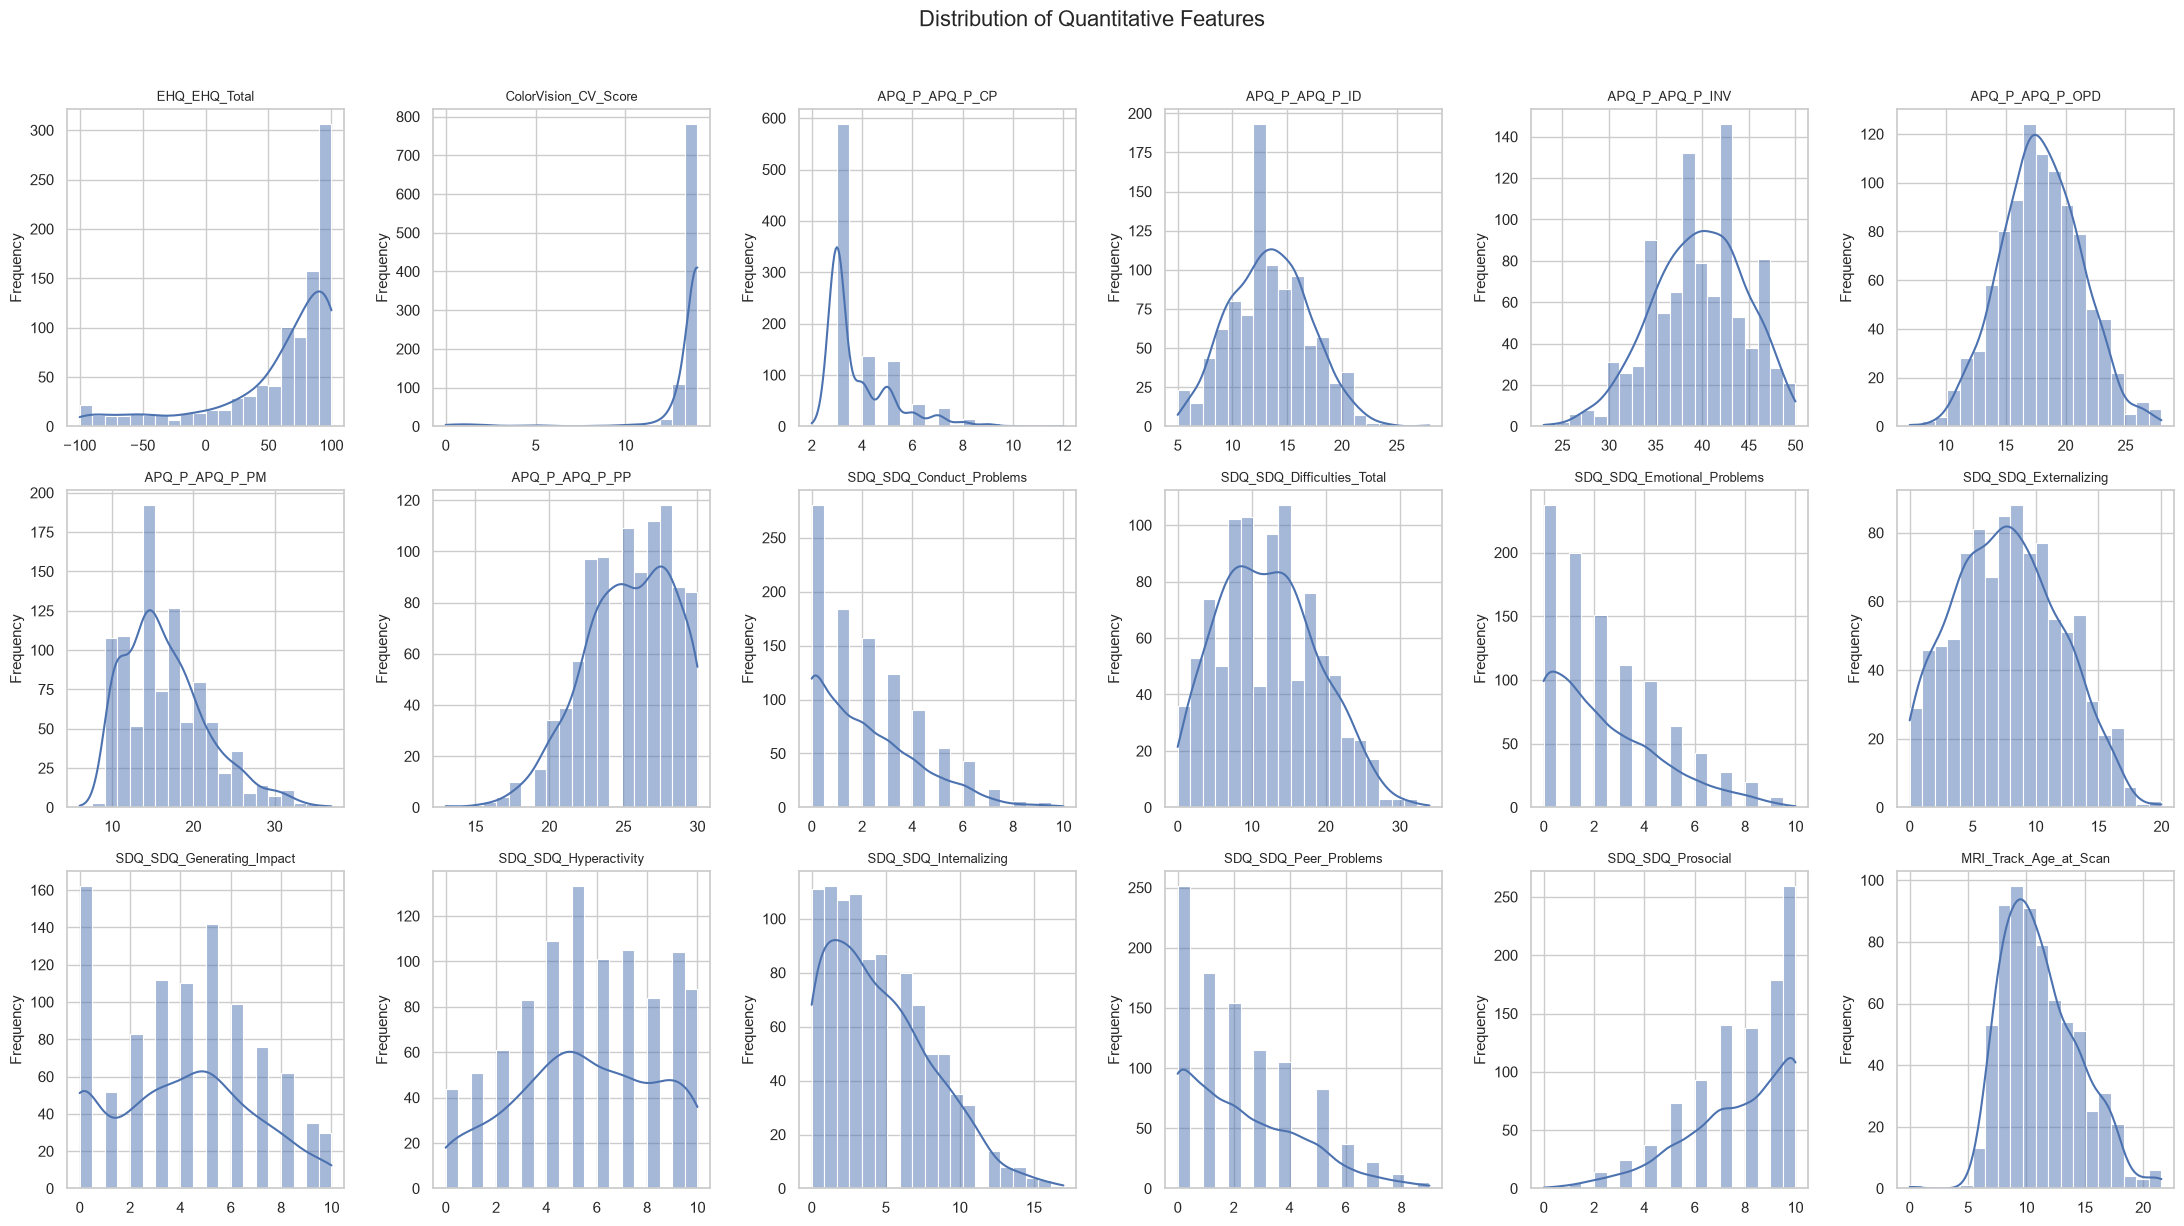

In [54]:
fig, axes = plt.subplots(3, 6, figsize=(22, 12))

for ax, feature in zip(axes.flatten(), quantitative_features):

    sns.histplot(
        data=df,
        x=feature,
        bins=20,
        kde=True,
        ax=ax
    )

    ax.set_title(feature, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("Frequency")

plt.suptitle(
    "Distribution of Quantitative Features",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "11_quantitative_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [55]:
outlier_results = []

for feature in quantitative_features:

    series = quantitative_df[feature].dropna()

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = series[
        (series < lower_bound) |
        (series > upper_bound)
    ]

    outlier_results.append({
        "Feature": feature,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": (
            len(outliers) / len(series) * 100
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(
    outlier_summary.sort_values(
        "Outlier_Percentage",
        ascending=False
    ).round(3)
)

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
1,ColorVision_CV_Score,14.000,14.000,0.000,14.000,14.000,174,18.239
2,APQ_P_APQ_P_CP,3.000,4.000,1.000,1.500,5.500,103,10.740
0,EHQ_EHQ_Total,44.470,93.340,48.870,-28.835,166.645,93,9.698
6,APQ_P_APQ_P_PM,13.000,19.000,6.000,4.000,28.000,32,3.337
8,SDQ_SDQ_Conduct_Problems,0.000,3.000,3.000,-4.500,7.500,13,1.350
5,APQ_P_APQ_P_OPD,16.000,20.000,4.000,10.000,26.000,10,1.043
17,MRI_Track_Age_at_Scan,8.789,13.465,4.677,1.774,20.481,7,1.023
10,SDQ_SDQ_Emotional_Problems,1.000,4.000,3.000,-3.500,8.500,9,0.935
14,SDQ_SDQ_Internalizing,2.000,7.000,5.000,-5.500,14.500,8,0.831
4,APQ_P_APQ_P_INV,36.000,43.000,7.000,25.500,53.500,3,0.313


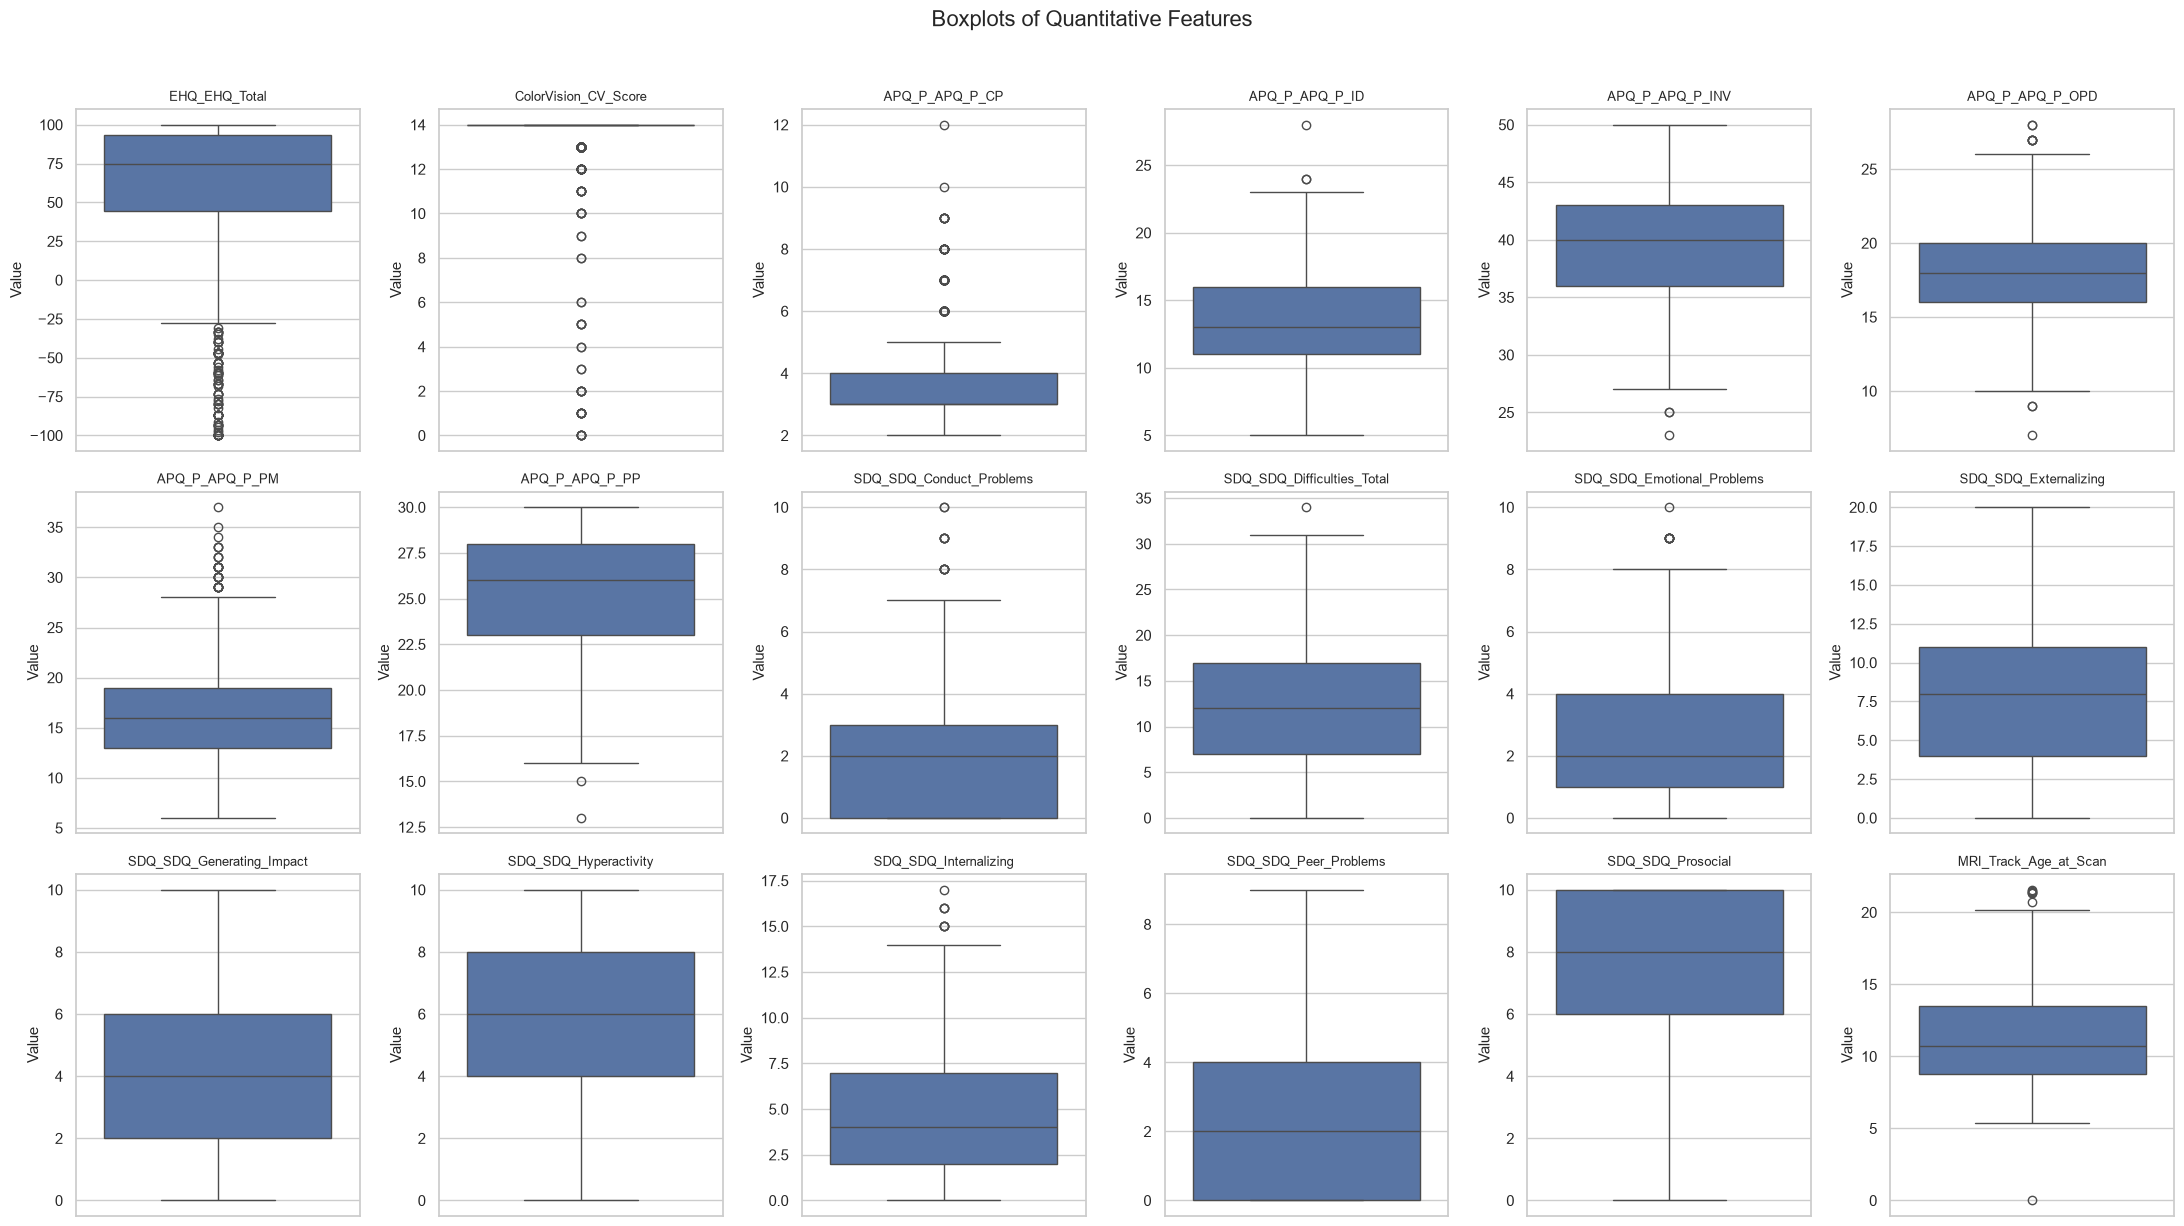

In [56]:
fig, axes = plt.subplots(3, 6, figsize=(22, 12))

for ax, feature in zip(axes.flatten(), quantitative_features):

    sns.boxplot(
        data=df,
        y=feature,
        ax=ax
    )

    ax.set_title(feature, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("Value")

plt.suptitle(
    "Boxplots of Quantitative Features",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "12_quantitative_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

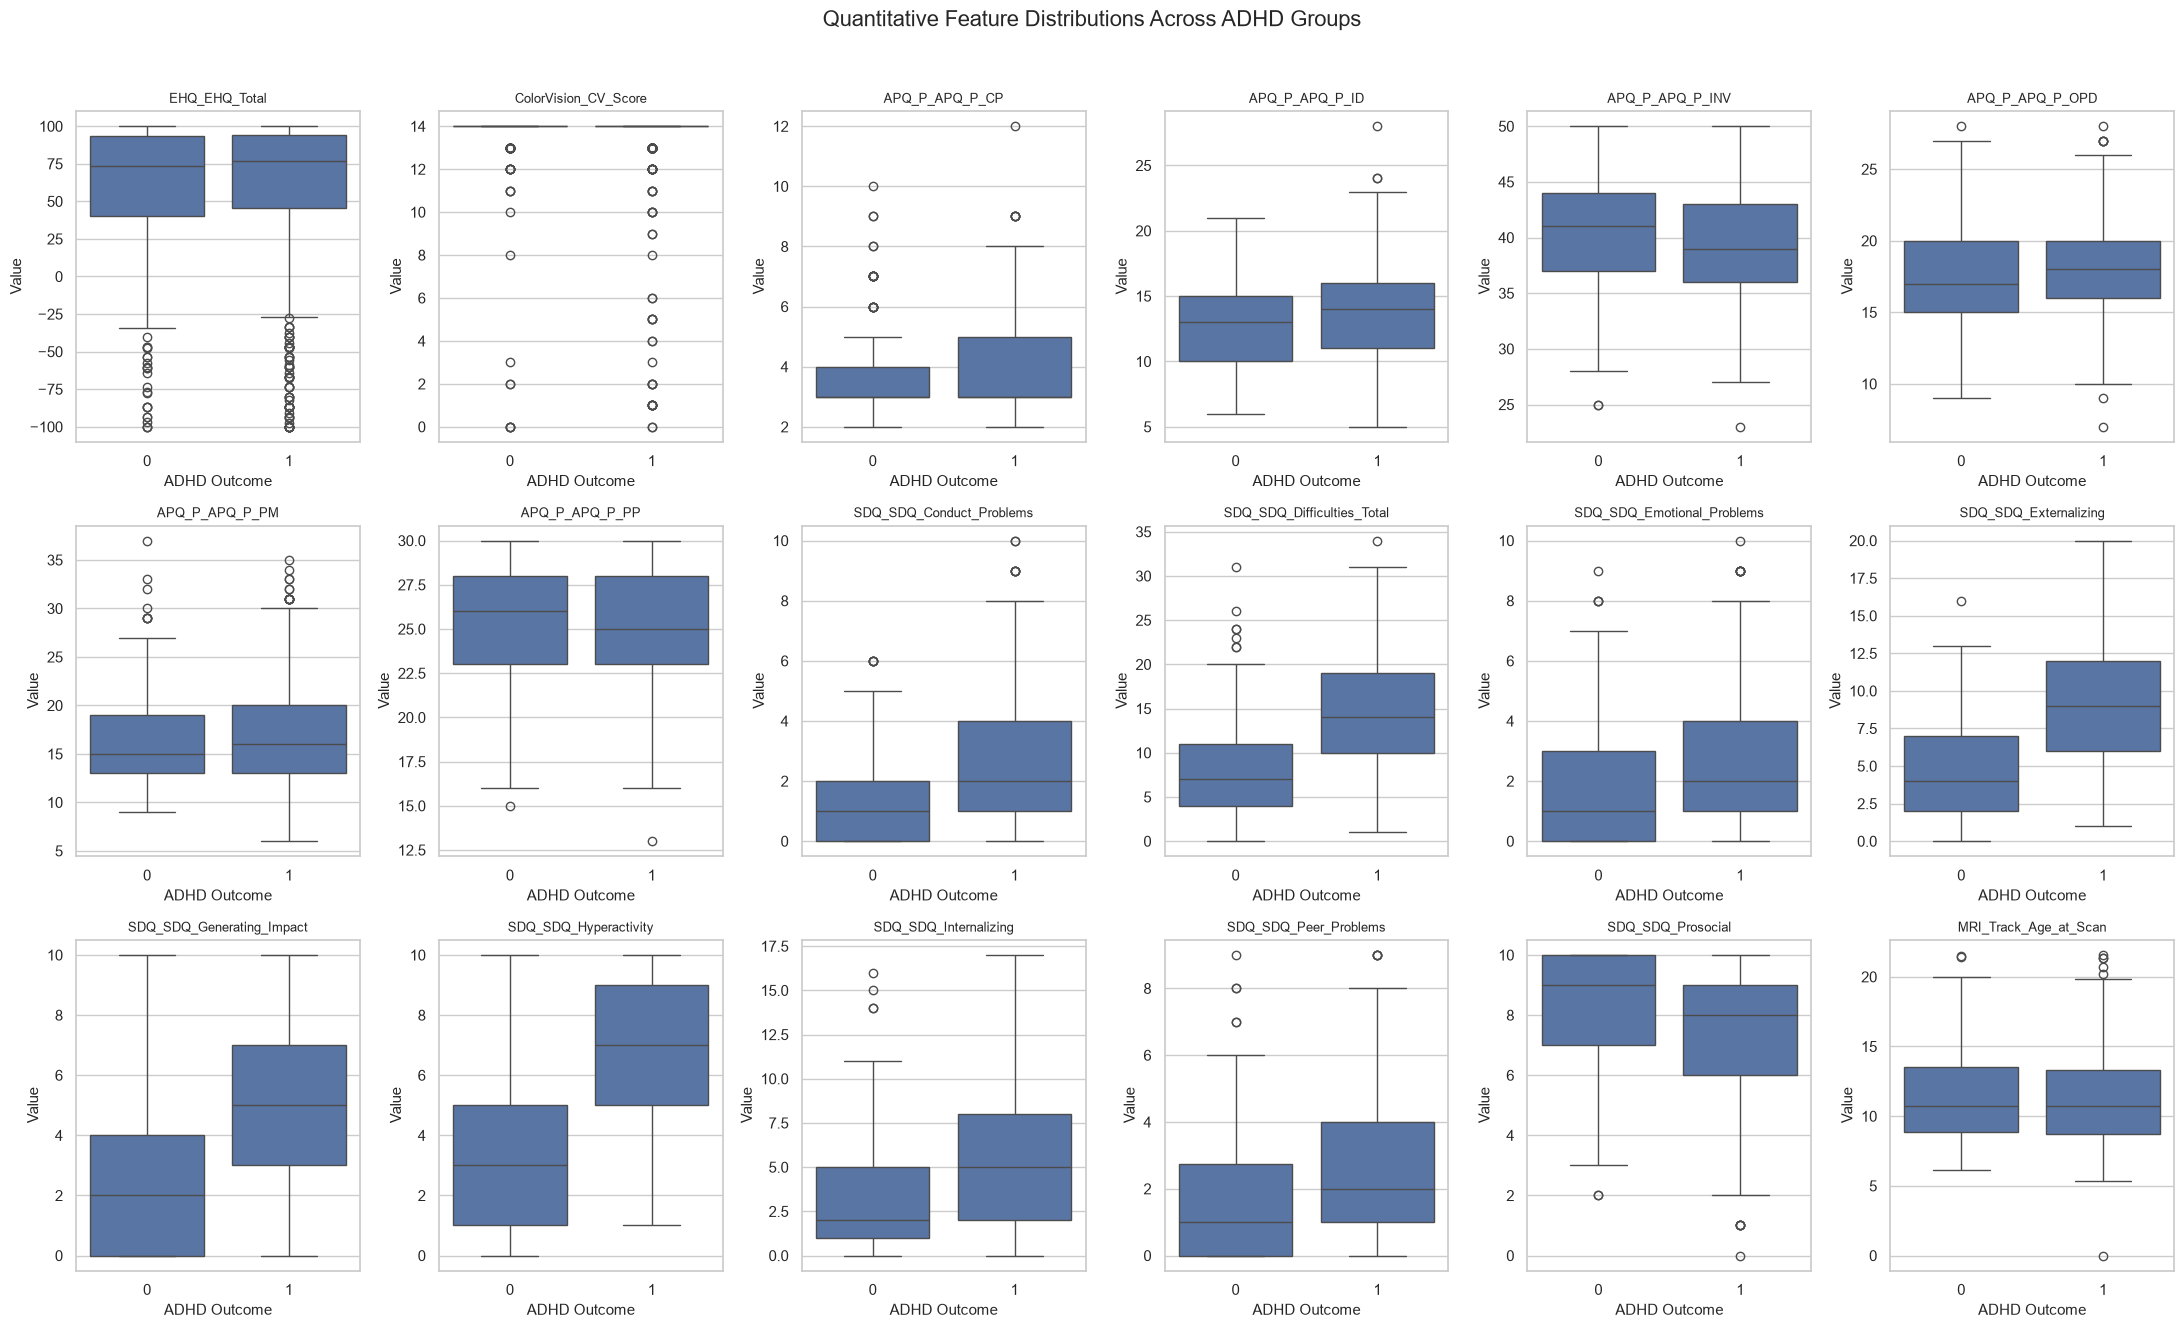

In [57]:
fig, axes = plt.subplots(3, 6, figsize=(22, 13))

for ax, feature in zip(axes.flatten(), quantitative_features):

    sns.boxplot(
        data=df,
        x="ADHD_Outcome",
        y=feature,
        ax=ax
    )

    ax.set_title(feature, fontsize=9)
    ax.set_xlabel("ADHD Outcome")
    ax.set_ylabel("Value")

plt.suptitle(
    "Quantitative Feature Distributions Across ADHD Groups",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "13_quantitative_by_adhd.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

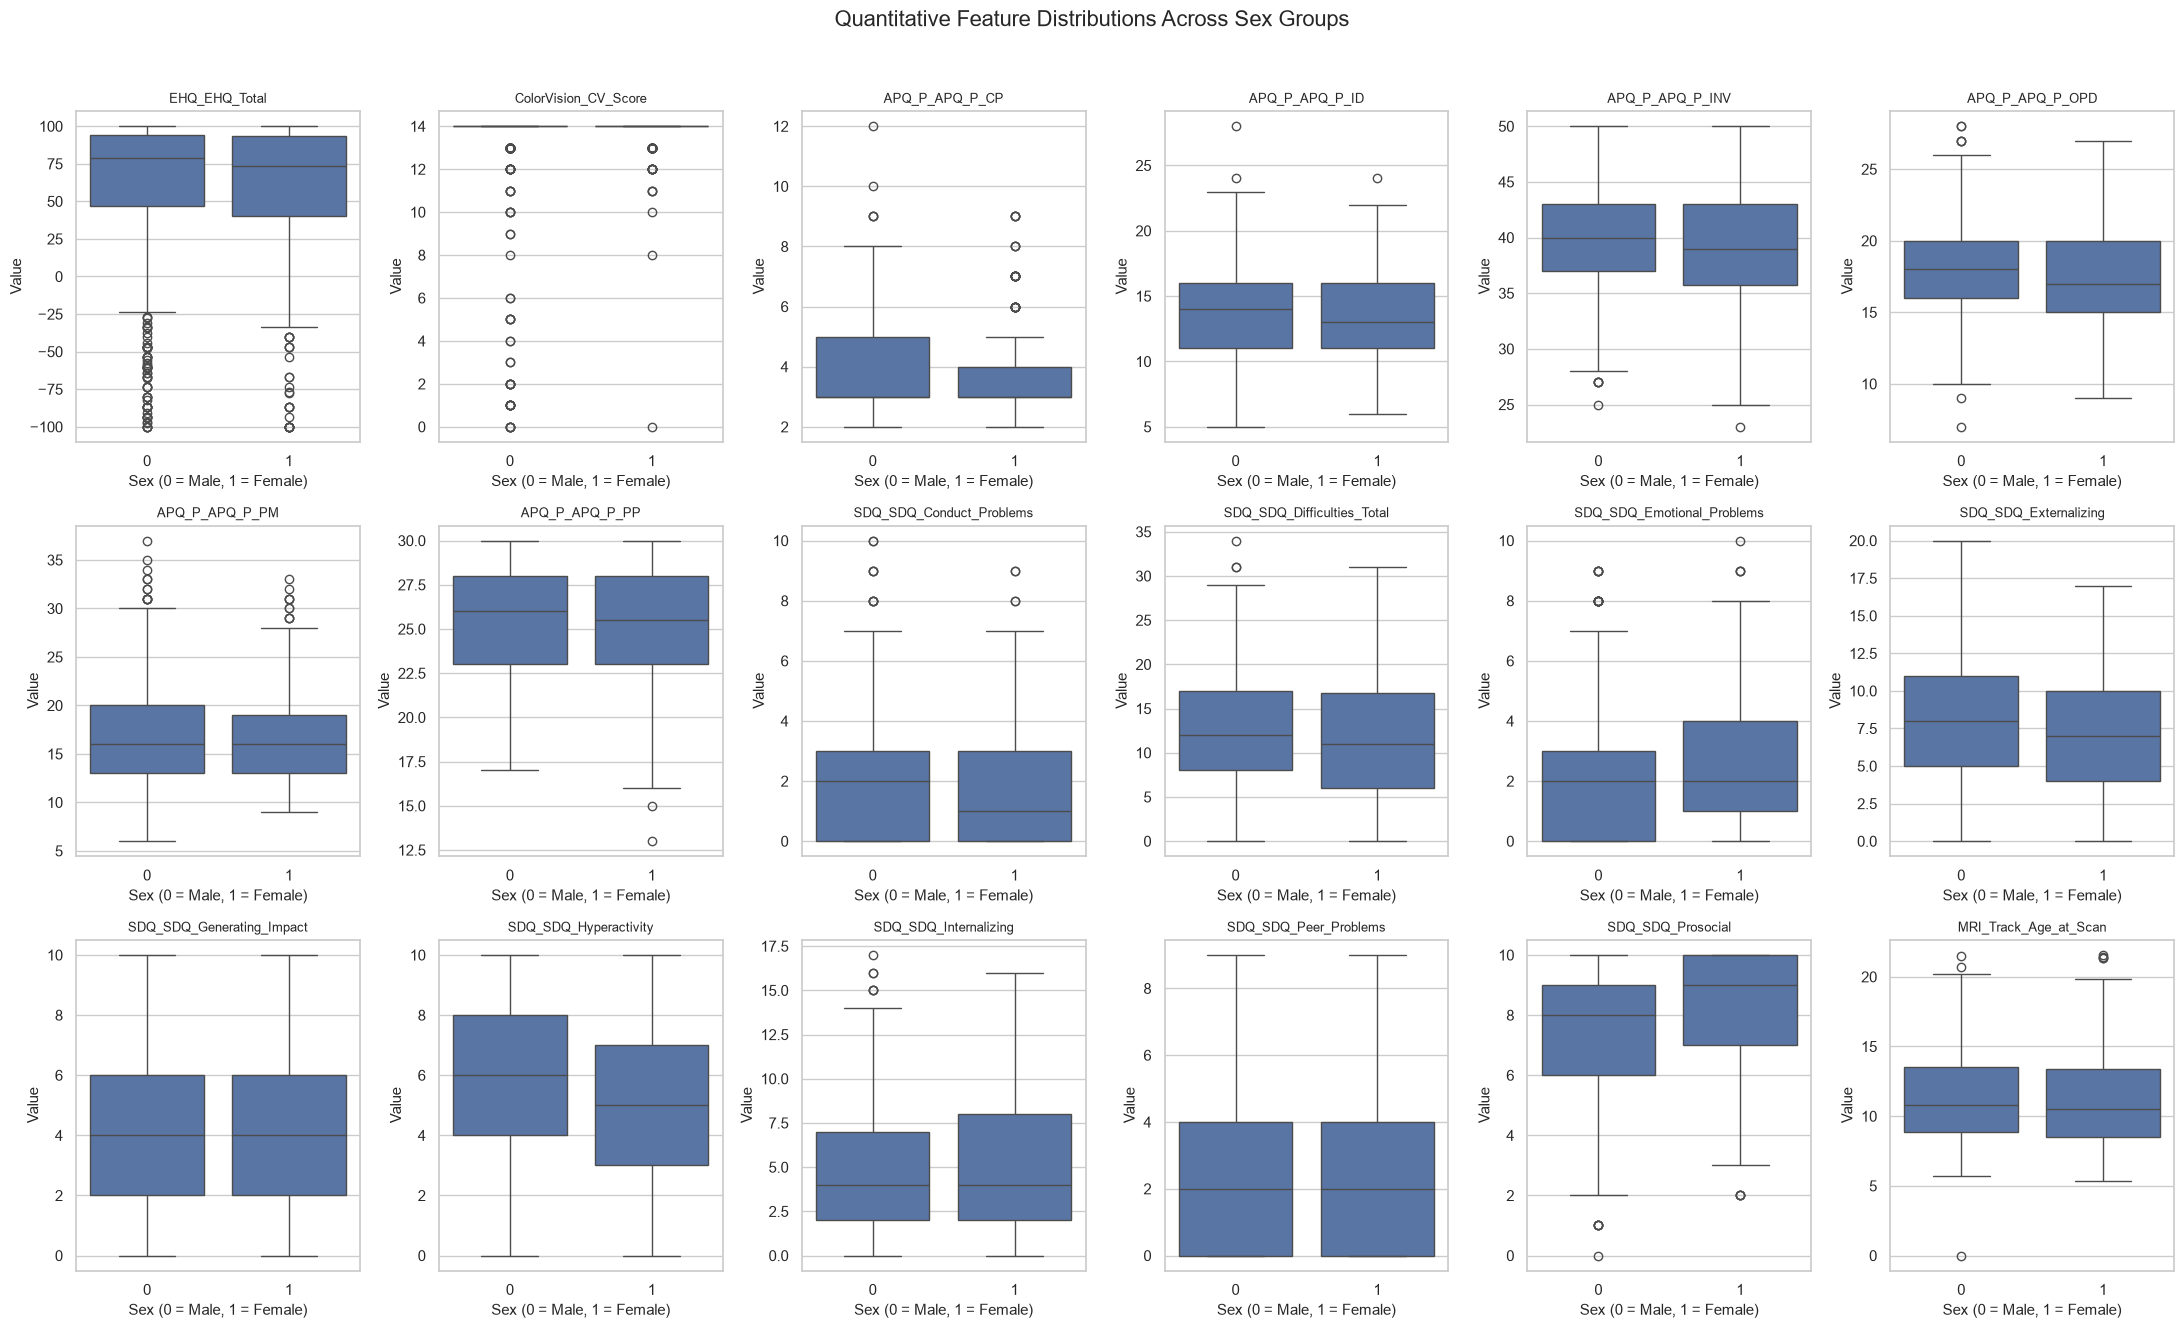

In [58]:
fig, axes = plt.subplots(3, 6, figsize=(22, 13))

for ax, feature in zip(axes.flatten(), quantitative_features):

    sns.boxplot(
        data=df,
        x="Sex_F",
        y=feature,
        ax=ax
    )

    ax.set_title(feature, fontsize=9)
    ax.set_xlabel("Sex (0 = Male, 1 = Female)")
    ax.set_ylabel("Value")

plt.suptitle(
    "Quantitative Feature Distributions Across Sex Groups",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "14_quantitative_by_sex.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

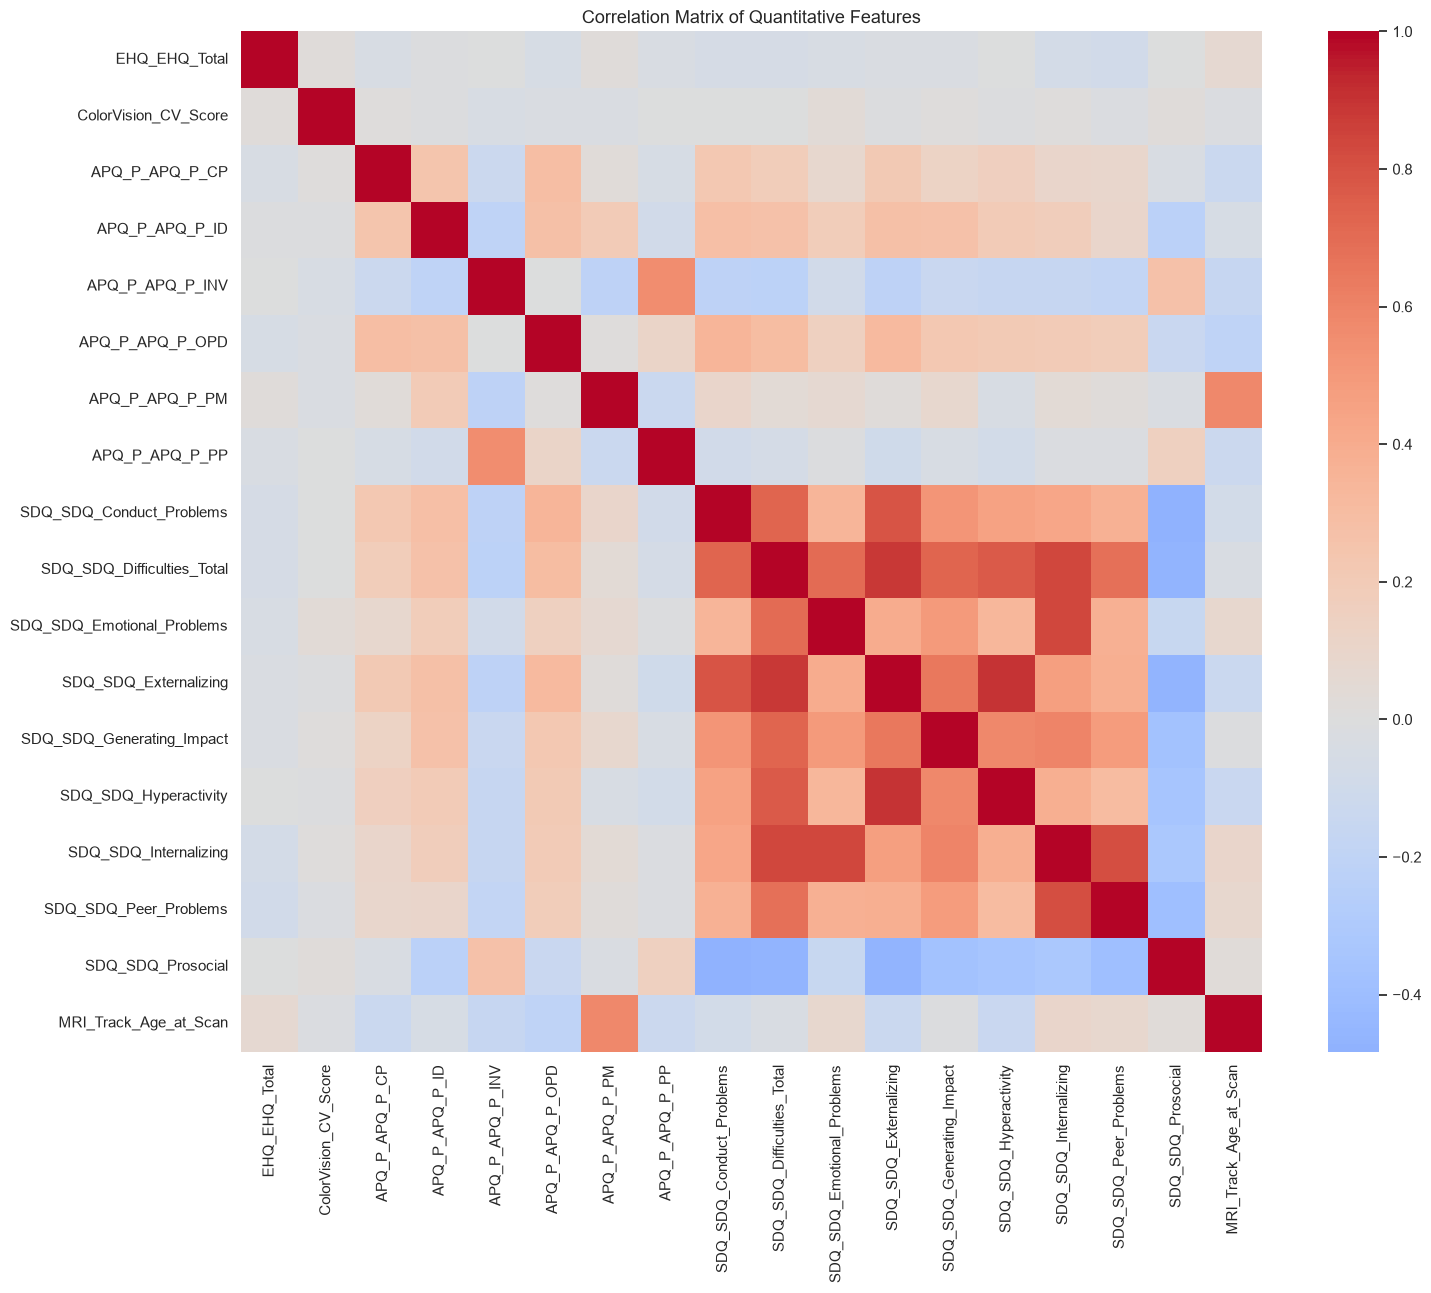

In [59]:
correlation_matrix = quantitative_df.corr(
    method="pearson"
)

plt.figure(figsize=(16, 13))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False,
    square=True
)

plt.title("Correlation Matrix of Quantitative Features")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "15_quantitative_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [60]:
# Extract upper triangle to avoid duplicate pairs

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

high_correlations = (
    upper_triangle
    .stack()
    .reset_index()
)

high_correlations.columns = [
    "Feature_1",
    "Feature_2",
    "Correlation"
]

high_correlations["Absolute_Correlation"] = (
    high_correlations["Correlation"].abs()
)

high_correlations = high_correlations.sort_values(
    "Absolute_Correlation",
    ascending=False
)

display(
    high_correlations[
        high_correlations["Absolute_Correlation"] >= 0.70
    ].round(3)
)

,Feature_1,Feature_2,Correlation,Absolute_Correlation
211,SDQ_SDQ_Externalizing,SDQ_SDQ_Hyperactivity,0.900,0.900
173,SDQ_SDQ_Difficulties_Total,SDQ_SDQ_Externalizing,0.882,0.882
194,SDQ_SDQ_Emotional_Problems,SDQ_SDQ_Internalizing,0.839,0.839
176,SDQ_SDQ_Difficulties_Total,SDQ_SDQ_Internalizing,0.835,0.835
267,SDQ_SDQ_Internalizing,SDQ_SDQ_Peer_Problems,0.819,0.819
155,SDQ_SDQ_Conduct_Problems,SDQ_SDQ_Externalizing,0.795,0.795
175,SDQ_SDQ_Difficulties_Total,SDQ_SDQ_Hyperactivity,0.774,0.774
153,SDQ_SDQ_Conduct_Problems,SDQ_SDQ_Difficulties_Total,0.730,0.730
174,SDQ_SDQ_Difficulties_Total,SDQ_SDQ_Generating_Impact,0.724,0.724
172,SDQ_SDQ_Difficulties_Total,SDQ_SDQ_Emotional_Problems,0.701,0.701



### 6.9 Observations and Findings

#### Descriptive Statistics

- EHQ exhibits strong negative skewness.
- Color Vision has a strong ceiling effect, with most observations concentrated at the maximum score.
- APQ Conduct Problems exhibits strong positive skewness.
- APQ Monitoring/Supervision shows moderate positive skewness.
- Most SDQ features have mild to moderate skewness.
- MRI age exhibits moderate positive skewness.

#### Distribution Analysis

- EHQ scores show substantial variation.
- Color Vision scores are concentrated at 14.
- APQ and SDQ features exhibit different distribution shapes.
- MRI age is concentrated around approximately 10–12 years.

#### Outlier Analysis

The IQR method identifies potential outliers in several features.

However, some findings require special interpretation:

- Color Vision has an IQR of zero, causing all non-14 observations to be flagged.
- Negative EHQ scores may be valid measurements.
- High questionnaire scores may represent genuine participant responses.

No automatic outlier removal is performed.

#### ADHD Group Comparisons

Several SDQ and APQ features show visible differences between ADHD-positive and ADHD-negative participants.

ADHD-positive participants generally exhibit higher median values in several difficulty-related questionnaire scores.

SDQ Prosocial shows a comparatively lower median in the ADHD-positive group.

These observations are exploratory and do not establish causation.

#### Sex Group Comparisons

Quantitative feature distributions exhibit substantial overlap between male and female participants.

Some differences are visible in selected questionnaire features, but their statistical and predictive significance remains to be evaluated.

#### Correlation Analysis

Strong positive correlations are observed among several SDQ features.

The strongest relationships include:

- SDQ Externalizing and Hyperactivity (0.900).
- SDQ Difficulties Total and Externalizing (0.882).
- SDQ Emotional Problems and Internalizing (0.839).

These relationships suggest overlapping information among questionnaire-derived features.

#### Preprocessing Implications

1. Preserve valid negative EHQ values.
2. Investigate the zero-IQR behaviour of Color Vision.
3. Verify the minimum MRI age value.
4. Avoid automatic outlier removal.
5. Investigate scaling and transformations where appropriate.
6. Evaluate multicollinearity during model development.
7. Compare feature selection strategies rather than automatically dropping correlated features.

### Conclusion

Quantitative metadata contains a mixture of skewed, approximately symmetric and highly concentrated distributions.

Several SDQ features exhibit strong correlations, while some questionnaire scores show visible differences across ADHD groups.

These findings will guide subsequent preprocessing, feature selection and model development experiments.


In [61]:
# Color Vision score distribution

print("COLOR VISION SCORE FREQUENCIES")
display(
    df["ColorVision_CV_Score"]
    .value_counts(dropna=False)
    .sort_index()
)

# MRI age distribution

print("\nMRI AGE: LOWEST VALUES")
display(
    df["MRI_Track_Age_at_Scan"]
    .value_counts(dropna=False)
    .sort_index()
    .head(15)
)

print("\nMRI AGE: HIGHEST VALUES")
display(
    df["MRI_Track_Age_at_Scan"]
    .sort_values(ascending=False)
    .head(10)
)

COLOR VISION SCORE FREQUENCIES


ColorVision_CV_Score
0.000       6
1.000       8
2.000       6
3.000       2
4.000       2
5.000       4
6.000       2
8.000       2
9.000       2
10.000      5
11.000      7
12.000     19
13.000    109
14.000    780
NaN        16
Name: count, dtype: int64


MRI AGE: LOWEST VALUES


MRI_Track_Age_at_Scan
0.000    1
5.360    1
5.682    1
5.842    1
5.959    1
6.022    1
6.131    1
6.173    1
6.192    1
6.213    1
6.236    1
6.285    1
6.362    1
6.362    1
6.413    1
Name: count, dtype: int64


MRI AGE: HIGHEST VALUES


213   21.564
806   21.464
155   21.417
159   21.335
964   21.330
456   20.694
565   20.171
967   20.004
156   19.839
417   19.021
Name: MRI_Track_Age_at_Scan, dtype: float64

In [62]:
pearson_corr = quantitative_df.corr(method="pearson")

spearman_corr = quantitative_df.corr(method="spearman")

# Compare the strongest relationships

comparison = pd.DataFrame({
    "Pearson": pearson_corr.where(
        np.triu(np.ones(pearson_corr.shape), k=1).astype(bool)
    ).stack(),

    "Spearman": spearman_corr.where(
        np.triu(np.ones(spearman_corr.shape), k=1).astype(bool)
    ).stack()
}).dropna()

comparison["Pearson_Abs"] = comparison["Pearson"].abs()

comparison = comparison.sort_values(
    "Pearson_Abs",
    ascending=False
)

display(comparison.head(15).round(3))

Pearson  Spearman  \
SDQ_SDQ_Externalizing      SDQ_SDQ_Hyperactivity         0.900     0.906   
SDQ_SDQ_Difficulties_Total SDQ_SDQ_Externalizing         0.882     0.883   
SDQ_SDQ_Emotional_Problems SDQ_SDQ_Internalizing         0.839     0.826   
SDQ_SDQ_Difficulties_Total SDQ_SDQ_Internalizing         0.835     0.827   
SDQ_SDQ_Internalizing      SDQ_SDQ_Peer_Problems         0.819     0.829   
SDQ_SDQ_Conduct_Problems   SDQ_SDQ_Externalizing         0.795     0.784   
SDQ_SDQ_Difficulties_Total SDQ_SDQ_Hyperactivity         0.774     0.783   
SDQ_SDQ_Conduct_Problems   SDQ_SDQ_Difficulties_Total    0.730     0.714   
SDQ_SDQ_Difficulties_Total SDQ_SDQ_Generating_Impact     0.724     0.733   
                           SDQ_SDQ_Emotional_Problems    0.701     0.688   
                           SDQ_SDQ_Peer_Problems         0.683     0.677   
SDQ_SDQ_Externalizing      SDQ_SDQ_Generating_Impact     0.647     0.650   
SDQ_SDQ_Generating_Impact  SDQ_SDQ_Internalizing         0.594     0.598   
                           SDQ_SDQ_Hyperactivity         0.582     0.587   
APQ_P_APQ_P_PM             MRI_Track_Age_at_Scan         0.582     0.560   

                                                       Pearson_Abs  
SDQ_SDQ_Externalizing      SDQ_SDQ_Hyperactivity             0.900  
SDQ_SDQ_Difficulties_Total SDQ_SDQ_Externalizing             0.882  
SDQ_SDQ_Emotional_Problems SDQ_SDQ_Internalizing             0.839  
SDQ_SDQ_Difficulties_Total SDQ_SDQ_Internalizing             0.835  
SDQ_SDQ_Internalizing      SDQ_SDQ_Peer_Problems             0.819  
SDQ_SDQ_Conduct_Problems   SDQ_SDQ_Externalizing             0.795  
SDQ_SDQ_Difficulties_Total SDQ_SDQ_Hyperactivity             0.774  
SDQ_SDQ_Conduct_Problems   SDQ_SDQ_Difficulties_Total        0.730  
SDQ_SDQ_Difficulties_Total SDQ_SDQ_Generating_Impact         0.724  
                           SDQ_SDQ_Emotional_Problems        0.701  
                           SDQ_SDQ_Peer_Problems             0.683  
SDQ_SDQ_Externalizing      SDQ_SDQ_Generating_Impact         0.647  
SDQ_SDQ_Generating_Impact  SDQ_SDQ_Internalizing             0.594  
                           SDQ_SDQ_Hyperactivity             0.582  
APQ_P_APQ_P_PM             MRI_Track_Age_at_Scan             0.582


### 6.10 Additional Investigations

#### Color Vision Score Distribution

The Color Vision feature has a strong concentration at the maximum score of 14.

- 780 out of 943 participants with available observations (82.7%) scored 14.
- The first quartile and third quartile are both 14.
- Consequently, the IQR is zero, causing the standard IQR method to flag all observations below 14.

This is a limitation of the outlier detection method for a highly concentrated discrete feature rather than evidence of invalid observations.

The feature will be retained for subsequent predictive evaluation.

#### MRI Age at Scan

The minimum MRI age is zero, occurring for one participant.

The remaining observed values begin at approximately 5.36 years, with a maximum of approximately 21.56 years.

The zero value requires verification against the original data and instrument documentation before preprocessing decisions are made.

#### Pearson and Spearman Correlation Comparison

The strongest SDQ feature relationships show similar Pearson and Spearman correlation coefficients.

This indicates that the strong associations are also present when examining rank-based monotonic relationships.

The findings reinforce the presence of overlapping information among several SDQ features.

#### Final Decisions

- Retain all observed Color Vision scores.
- Investigate the single zero MRI age observation.
- Preserve valid EHQ negative scores.
- Avoid automatic outlier removal.
- Retain correlated SDQ features initially.
- Evaluate feature redundancy and predictive contributions during model development.

### 6.11 Section Conclusion

The quantitative metadata analysis identified skewed distributions, potential outliers, ceiling effects and strong correlations among questionnaire-derived features.

These findings provide a basis for subsequent preprocessing and feature engineering decisions.



# 7. Functional Connectome Analysis

The functional connectome dataset contains pairwise connectivity measurements between brain regions for each participant.

Unlike the quantitative metadata, which contains only 18 features, the connectome dataset contains 19,900 connectivity features per participant.

This section investigates:

1. The structure and integrity of connectivity measurements.
2. Connectivity value distributions.
3. Participant-level connectivity characteristics.
4. Differences in connectivity across target groups.
5. Feature variability and redundancy.
6. Implications for dimensionality reduction and feature selection.

The objective is to understand the high-dimensional connectivity data before selecting appropriate preprocessing and modelling strategies.


In [66]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data")

TRAIN_CONNECTOME_PATH = (
    DATA_DIR / "TRAIN" /
    "TRAIN_FUNCTIONAL_CONNECTOME_MATRICES_new_36P_Pearson.csv"
)

TEST_CONNECTOME_PATH = (
    DATA_DIR / "TEST" /
    "TEST_FUNCTIONAL_CONNECTOME_MATRICES.csv"
)

print("Train file exists:", TRAIN_CONNECTOME_PATH.exists())
print("Test file exists:", TEST_CONNECTOME_PATH.exists())

Train file exists: True
Test file exists: True


In [69]:
print("TRAIN CONNECTOME")
print("-" * 50)

print("Shape:", train_connectome.shape)
print("Participants:", train_connectome["participant_id"].nunique())
print("Total columns:", len(train_connectome.columns))

print("\nTEST CONNECTOME")
print("-" * 50)

print("Shape:", test_connectome.shape)
print("Participants:", test_connectome["participant_id"].nunique())
print("Total columns:", len(test_connectome.columns))

connectome_features = [
    col for col in train_connectome.columns
    if col != "participant_id"
]

print("\nNumber of connectivity features:", len(connectome_features))

TRAIN CONNECTOME
--------------------------------------------------
Shape: (1213, 19901)
Participants: 1213
Total columns: 19901

TEST CONNECTOME
--------------------------------------------------
Shape: (304, 19901)
Participants: 304
Total columns: 19901

Number of connectivity features: 19900


In [70]:
import re
from math import comb

pattern = r"(\d+)throw_(\d+)thcolumn"

connections = []

for col in connectome_features:

    match = re.fullmatch(pattern, col)

    if match is None:
        print("Unexpected column:", col)
        continue

    row_idx = int(match.group(1))
    col_idx = int(match.group(2))

    connections.append((row_idx, col_idx))

print("Total parsed connections:", len(connections))

print("Unique brain regions:",
      len(set(
          idx
          for pair in connections
          for idx in pair
      )))

print("Expected connections for 200 regions:", comb(200, 2))

print("All connections have row < column:",
      all(r < c for r, c in connections))

print("Unique connections:",
      len(set(connections)))

Total parsed connections: 19900
Unique brain regions: 200
Expected connections for 200 regions: 19900
All connections have row < column: True
Unique connections: 19900


In [71]:
print("DUPLICATE PARTICIPANT IDS")
print("-" * 50)

print("Train:",
      train_connectome["participant_id"].duplicated().sum())

print("Test:",
      test_connectome["participant_id"].duplicated().sum())


print("\nMISSING VALUES")
print("-" * 50)

print("Train:",
      train_connectome[connectome_features].isna().sum().sum())

print("Test:",
      test_connectome[connectome_features].isna().sum().sum())


print("\nCOLUMN CONSISTENCY")
print("-" * 50)

print(
    "Same feature columns:",
    train_connectome.columns.tolist()
    == test_connectome.columns.tolist()
)


print("\nINFINITE VALUES")
print("-" * 50)

print(
    "Train:",
    np.isinf(
        train_connectome[connectome_features].to_numpy()
    ).sum()
)

print(
    "Test:",
    np.isinf(
        test_connectome[connectome_features].to_numpy()
    ).sum()
)

DUPLICATE PARTICIPANT IDS
--------------------------------------------------
Train: 0
Test: 0

MISSING VALUES
--------------------------------------------------
Train: 0
Test: 0

COLUMN CONSISTENCY
--------------------------------------------------
Same feature columns: True

INFINITE VALUES
--------------------------------------------------
Train: 0
Test: 0


In [72]:
train_conn_values = train_connectome[connectome_features]

print("CONNECTIVITY VALUE SUMMARY")
print("-" * 50)

display(
    train_conn_values.describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
    ).T.head(15).round(4)
)

print("\nOverall minimum:",
      train_conn_values.min().min())

print("Overall maximum:",
      train_conn_values.max().max())

print("Overall mean:",
      train_conn_values.mean().mean())

print("Overall standard deviation:",
      train_conn_values.stack().std())

CONNECTIVITY VALUE SUMMARY
--------------------------------------------------


,count,mean,std,min,1%,25%,50%,75%,99%,max
0throw_1thcolumn,1213.000,0.185,0.238,-0.657,-0.371,0.028,0.193,0.359,0.657,0.824
0throw_2thcolumn,1213.000,0.583,0.173,-0.225,0.058,0.495,0.607,0.711,0.867,0.907
0throw_3thcolumn,1213.000,0.439,0.235,-0.517,-0.164,0.286,0.470,0.627,0.825,0.885
0throw_4thcolumn,1213.000,0.450,0.212,-0.440,-0.184,0.314,0.479,0.604,0.817,0.877
0throw_5thcolumn,1213.000,0.585,0.196,-0.486,-0.060,0.487,0.623,0.726,0.860,0.894
0throw_6thcolumn,1213.000,0.554,0.158,-0.059,0.113,0.462,0.577,0.670,0.822,0.882
0throw_7thcolumn,1213.000,0.509,0.179,-0.181,-0.002,0.406,0.534,0.636,0.824,0.893
0throw_8thcolumn,1213.000,0.283,0.190,-0.342,-0.156,0.153,0.291,0.424,0.682,0.803
0throw_9thcolumn,1213.000,0.426,0.203,-0.353,-0.186,0.319,0.453,0.571,0.779,0.854
0throw_10thcolumn,1213.000,0.255,0.208,-0.579,-0.305,0.124,0.269,0.403,0.669,0.828



Overall minimum: -0.8753956628213888
Overall maximum: 0.9590231760120752
Overall mean: 0.0226945377180422
Overall standard deviation: 0.2512661121059438



### 7.1 Connectome Structure and Data Integrity

The functional connectome dataset contains pairwise connectivity measurements between 200 brain regions.

#### Dataset Structure

- Training participants: 1,213
- Testing participants: 304
- Total columns: 19,901
- Connectivity features: 19,900
- Brain regions: 200

The number of connectivity features was verified using:

C(200,2) = 200 × 199 / 2 = 19,900

This confirms that the dataset stores unique off-diagonal connections from a symmetric 200 × 200 connectivity matrix, without redundant lower-triangular entries.

#### Data Integrity Checks

The following checks were performed:

1. No duplicate participant IDs were found.
2. No missing connectivity values were found.
3. No infinite connectivity values were found.
4. Training and testing datasets contain identical feature columns.
5. All 19,900 connection pairs were successfully parsed.
6. Every connection satisfies row index < column index.
7. All connection pairs are unique.

#### Connectivity Value Summary

- Minimum: -0.8754
- Maximum: 0.9590
- Overall mean: 0.0227
- Overall standard deviation: 0.2513

All observed values fall within the theoretical range of Pearson correlation coefficients [-1, 1].

#### Conclusion

The connectome data has a consistent triangular representation of 200 brain regions and passes all major structural integrity checks.

No missing-value imputation is required for the connectivity features based on the current dataset.

Further investigation will focus on connectivity distributions, participant-level characteristics, target-group differences and dimensionality reduction.


In [73]:
# Convert to NumPy for efficient sampling

conn_array = train_connectome[connectome_features].to_numpy()

rng = np.random.default_rng(42)

n_samples = 1_000_000

row_indices = rng.integers(
    0, conn_array.shape[0], n_samples
)

col_indices = rng.integers(
    0, conn_array.shape[1], n_samples
)

connectivity_sample = conn_array[
    row_indices,
    col_indices
]

print("Sample size:", len(connectivity_sample))

print("Sample mean:", connectivity_sample.mean())

print("Sample standard deviation:", connectivity_sample.std())

print("Positive connections:",
      (connectivity_sample > 0).mean() * 100, "%")

print("Negative connections:",
      (connectivity_sample < 0).mean() * 100, "%")

Sample size: 1000000
Sample mean: 0.02244935113468665
Sample standard deviation: 0.25122480429770006
Positive connections: 50.4026 %
Negative connections: 49.5936 %


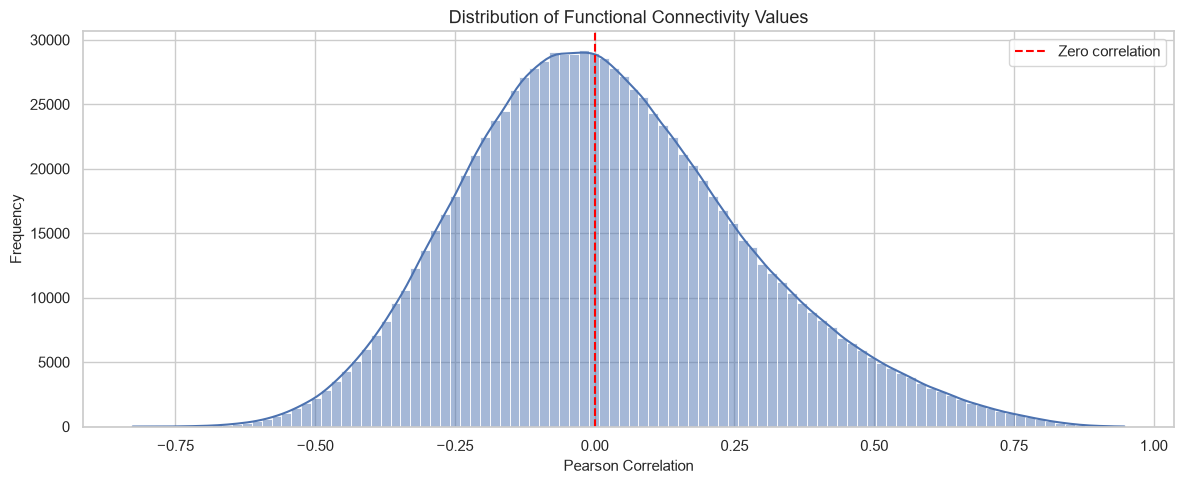

In [74]:
plt.figure(figsize=(12, 5))

sns.histplot(
    connectivity_sample,
    bins=100,
    kde=True
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero correlation"
)

plt.title("Distribution of Functional Connectivity Values")
plt.xlabel("Pearson Correlation")
plt.ylabel("Frequency")

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "16_connectivity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Count
Positive,504026
Negative,495936
Zero,38


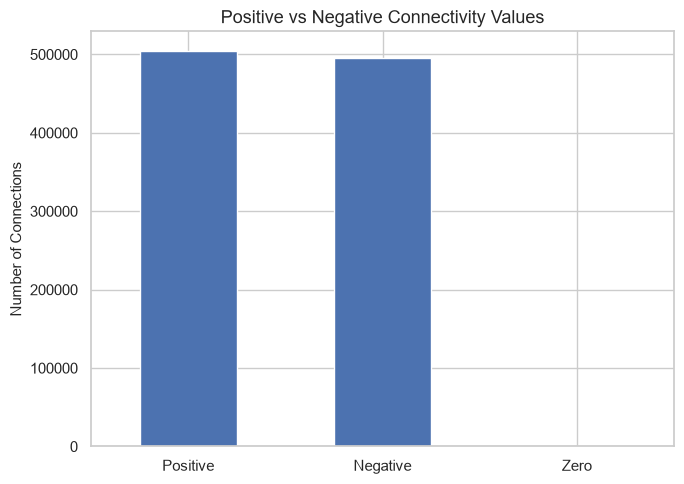

In [75]:
positive_count = (connectivity_sample > 0).sum()
negative_count = (connectivity_sample < 0).sum()
zero_count = (connectivity_sample == 0).sum()

connectivity_sign = pd.Series({
    "Positive": positive_count,
    "Negative": negative_count,
    "Zero": zero_count
})

display(
    connectivity_sign.to_frame("Count")
)

plt.figure(figsize=(7, 5))

connectivity_sign.plot(
    kind="bar",
    rot=0
)

plt.title("Positive vs Negative Connectivity Values")
plt.ylabel("Number of Connections")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "17_connectivity_sign_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [76]:
participant_connectivity_stats = pd.DataFrame({
    "participant_id": train_connectome["participant_id"],

    "Mean_Connectivity": train_connectome[
        connectome_features
    ].mean(axis=1),

    "Std_Connectivity": train_connectome[
        connectome_features
    ].std(axis=1),

    "Median_Connectivity": train_connectome[
        connectome_features
    ].median(axis=1),

    "Min_Connectivity": train_connectome[
        connectome_features
    ].min(axis=1),

    "Max_Connectivity": train_connectome[
        connectome_features
    ].max(axis=1),

    "Mean_Absolute_Connectivity": train_connectome[
        connectome_features
    ].abs().mean(axis=1),

    "Positive_Connectivity_Percentage": (
        train_connectome[connectome_features] > 0
    ).mean(axis=1) * 100,

    "Negative_Connectivity_Percentage": (
        train_connectome[connectome_features] < 0
    ).mean(axis=1) * 100
})

display(participant_connectivity_stats.head())

print(
    "Participant statistics shape:",
    participant_connectivity_stats.shape
)

,participant_id,Mean_Connectivity,Std_Connectivity,Median_Connectivity,Min_Connectivity,Max_Connectivity,Mean_Absolute_Connectivity,Positive_Connectivity_Percentage,Negative_Connectivity_Percentage
0,70z8Q2xdTXM3,0.030,0.216,0.015,-0.637,0.865,0.172,52.940,47.060
1,WHWymJu6zNZi,0.028,0.214,0.014,-0.745,0.868,0.171,52.518,47.482
2,4PAQp1M6EyAo,0.023,0.247,-0.011,-0.709,0.889,0.194,48.025,51.975
3,obEacy4Of68I,0.001,0.257,-0.024,-0.713,0.893,0.205,46.402,53.598
4,s7WzzDcmDOhF,0.013,0.240,0.001,-0.714,0.879,0.193,50.131,49.869


Participant statistics shape: (1213, 9)


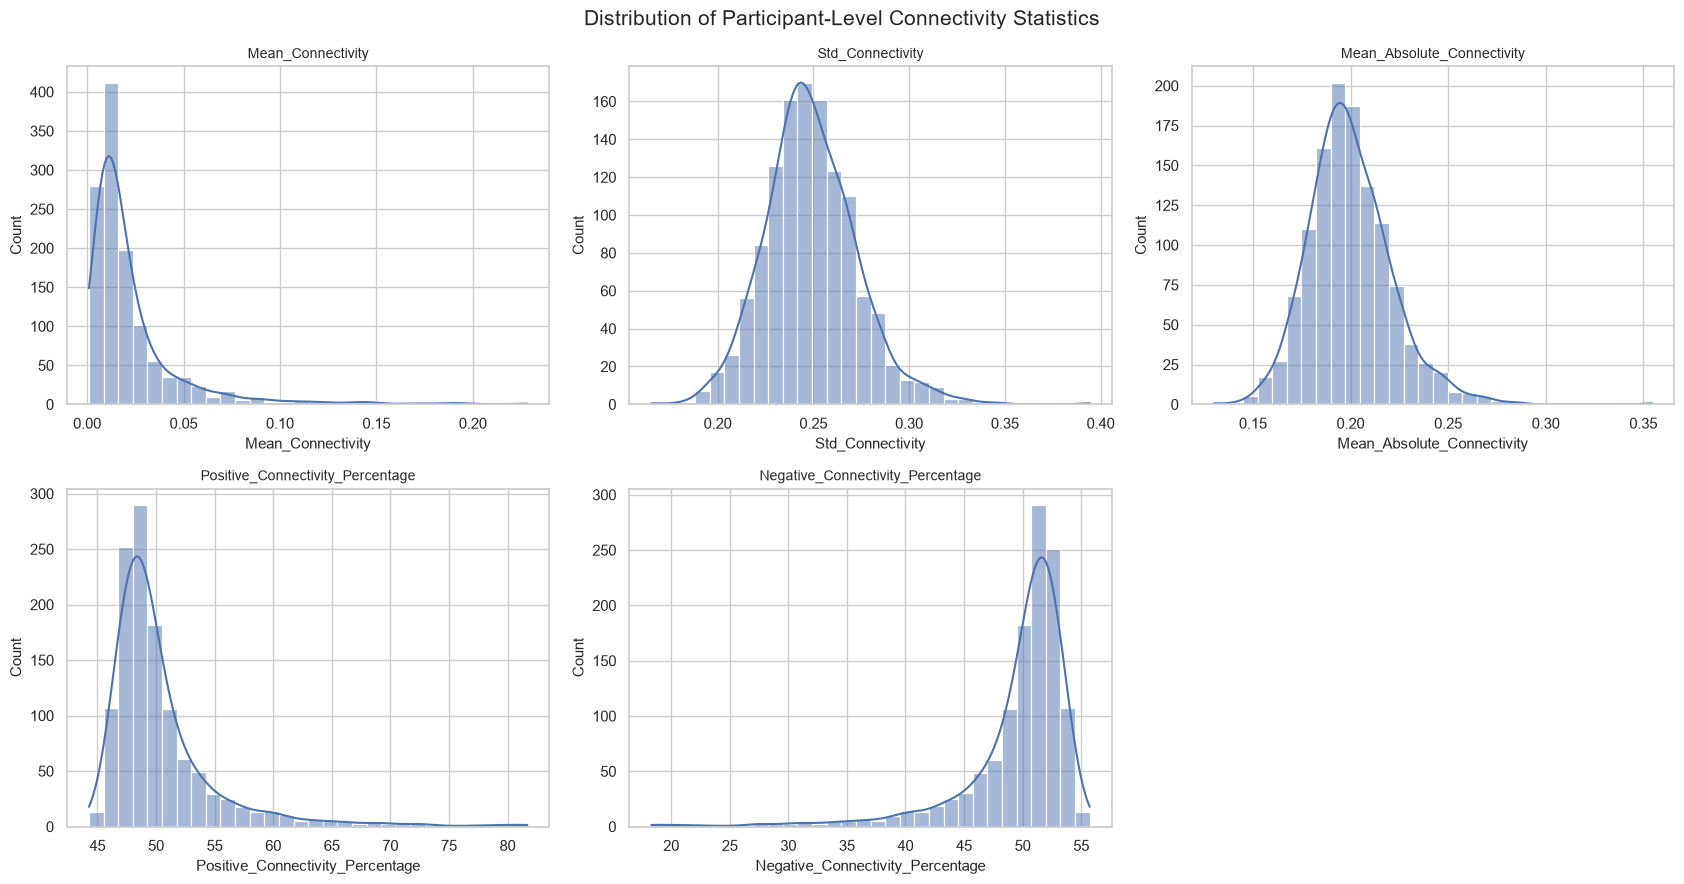

In [77]:
participant_features = [
    "Mean_Connectivity",
    "Std_Connectivity",
    "Mean_Absolute_Connectivity",
    "Positive_Connectivity_Percentage",
    "Negative_Connectivity_Percentage"
]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for ax, feature in zip(
    axes.flatten(),
    participant_features
):

    sns.histplot(
        participant_connectivity_stats[feature],
        kde=True,
        bins=30,
        ax=ax
    )

    ax.set_title(feature, fontsize=10)

axes.flatten()[-1].set_visible(False)

plt.suptitle(
    "Distribution of Participant-Level Connectivity Statistics",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "18_participant_connectivity_statistics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 7.2 Connectivity Value Distribution

A random sample of 1,000,000 connectivity values was selected from the training connectome dataset for distribution analysis.

#### Overall Distribution

- Sample mean: 0.02245
- Sample standard deviation: 0.25122
- Positive connectivity: 50.40%
- Negative connectivity: 49.59%

The connectivity distribution is broadly unimodal and approximately bell-shaped, with a slight asymmetry.

Positive and negative connectivity values are almost equally represented, with a slightly higher proportion of positive values.

The overall mean is close to zero, indicating that positive and negative measurements approximately balance out when pooled.

#### Conclusion

Connectivity measurements exhibit considerable variation despite their relatively small overall mean.

### 7.3 Participant-Level Connectivity Analysis

Eight summary statistics were calculated for each of the 1,213 training participants.

These statistics describe the overall connectivity profile of each participant.

#### Key Observations

1. Mean Connectivity: The distribution is positively skewed, with most participants having relatively small average connectivity values.
2. Standard Deviation: Participant-level connectivity variability is concentrated around approximately 0.24–0.25.
3. Mean Absolute Connectivity: Most participants exhibit values around 0.19–0.21.
4. Positive Connectivity Percentage: Most participants have approximately 48–51% positive connections.
5. Negative Connectivity Percentage: Its distribution complements the positive connectivity percentage.

#### Feature Redundancy

Positive and negative connectivity percentages are mathematically complementary when no connectivity values are exactly zero.

Therefore, retaining both features would introduce redundant information.

Only Positive Connectivity Percentage will be retained if these participant-level summary features are used in subsequent modelling.

#### Conclusion

Participant-level connectivity summaries reveal variation in average connectivity strength and connectivity magnitude across participants.

These features provide a compact representation of connectivity patterns, although they cannot replace the original 19,900 connectivity measurements.


In [78]:
training_solutions = pd.read_excel(
    DATA_DIR / "TRAIN" / "TRAINING_SOLUTIONS.xlsx"
)

connectome_analysis = participant_connectivity_stats.merge(
    training_solutions[
        ["participant_id", "ADHD_Outcome", "Sex_F"]
    ],
    on="participant_id",
    how="left",
    validate="one_to_one"
)

assert connectome_analysis[
    ["ADHD_Outcome", "Sex_F"]
].notna().all().all()

print("Analysis shape:", connectome_analysis.shape)

display(
    connectome_analysis[
        ["ADHD_Outcome", "Sex_F"]
    ].value_counts().sort_index()
)

Analysis shape: (1213, 11)


ADHD_Outcome  Sex_F
0             0        216
              1        166
1             0        581
              1        250
Name: count, dtype: int64

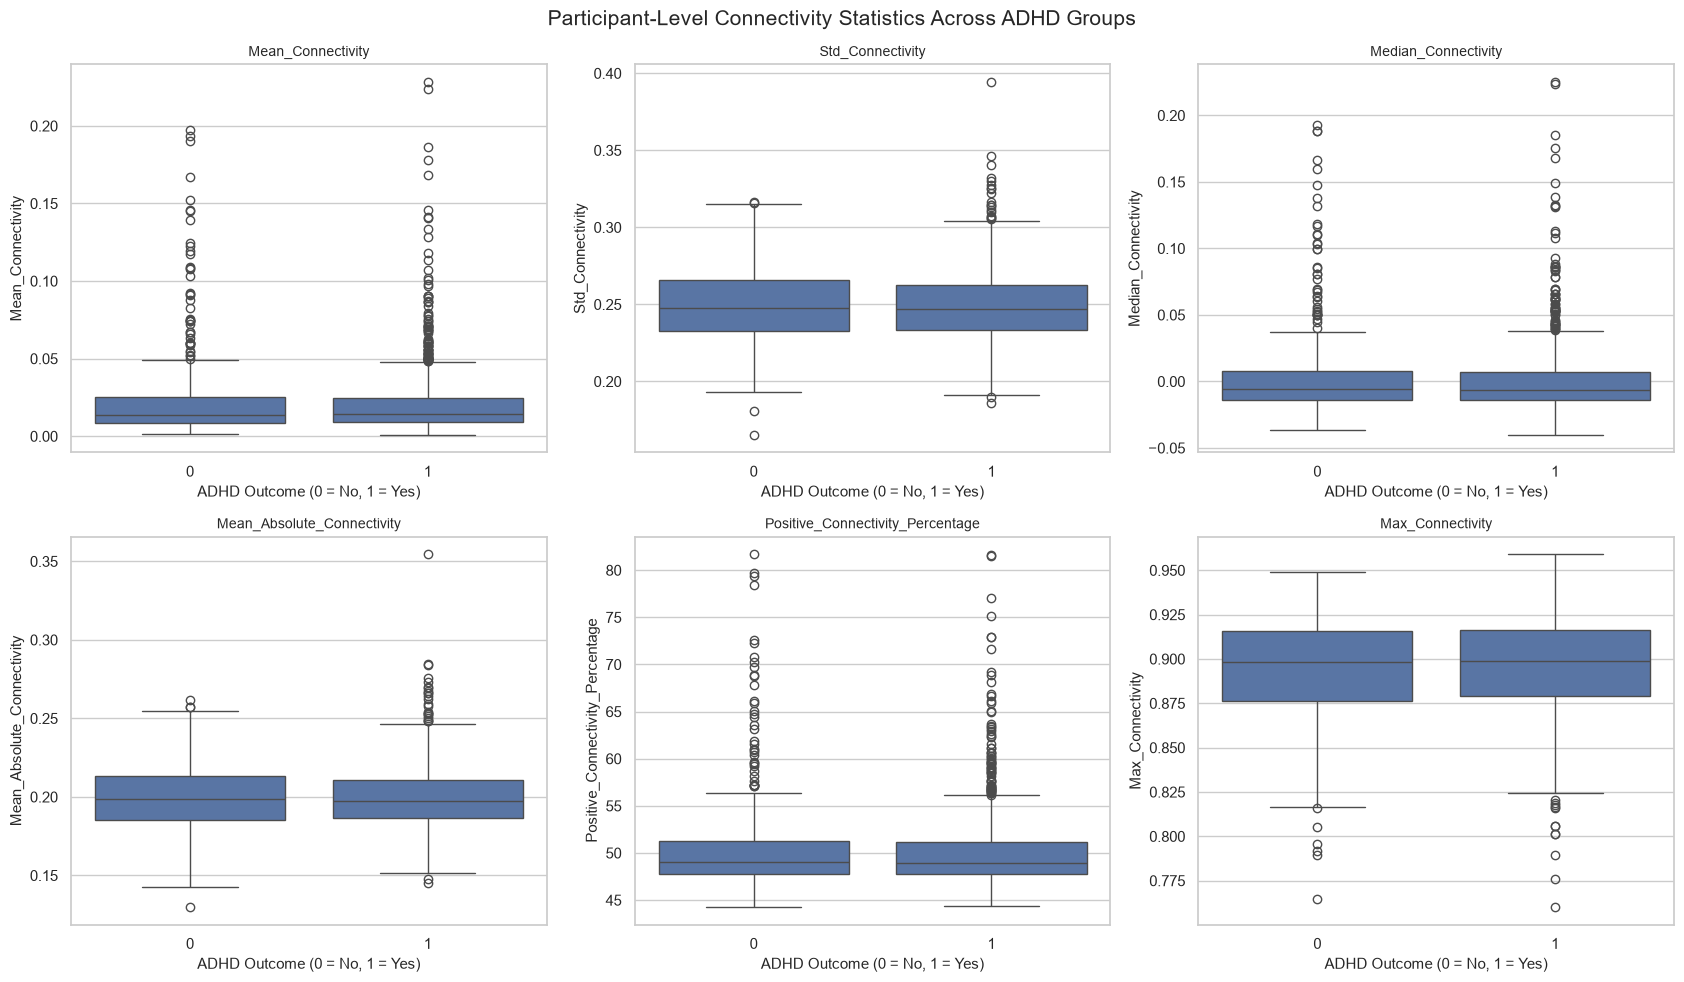

In [79]:
summary_features = [
    "Mean_Connectivity",
    "Std_Connectivity",
    "Median_Connectivity",
    "Mean_Absolute_Connectivity",
    "Positive_Connectivity_Percentage",
    "Max_Connectivity"
]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, feature in zip(axes.flatten(), summary_features):

    sns.boxplot(
        data=connectome_analysis,
        x="ADHD_Outcome",
        y=feature,
        ax=ax
    )

    ax.set_title(feature, fontsize=10)
    ax.set_xlabel("ADHD Outcome (0 = No, 1 = Yes)")

plt.suptitle(
    "Participant-Level Connectivity Statistics Across ADHD Groups",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "19_connectivity_by_adhd.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

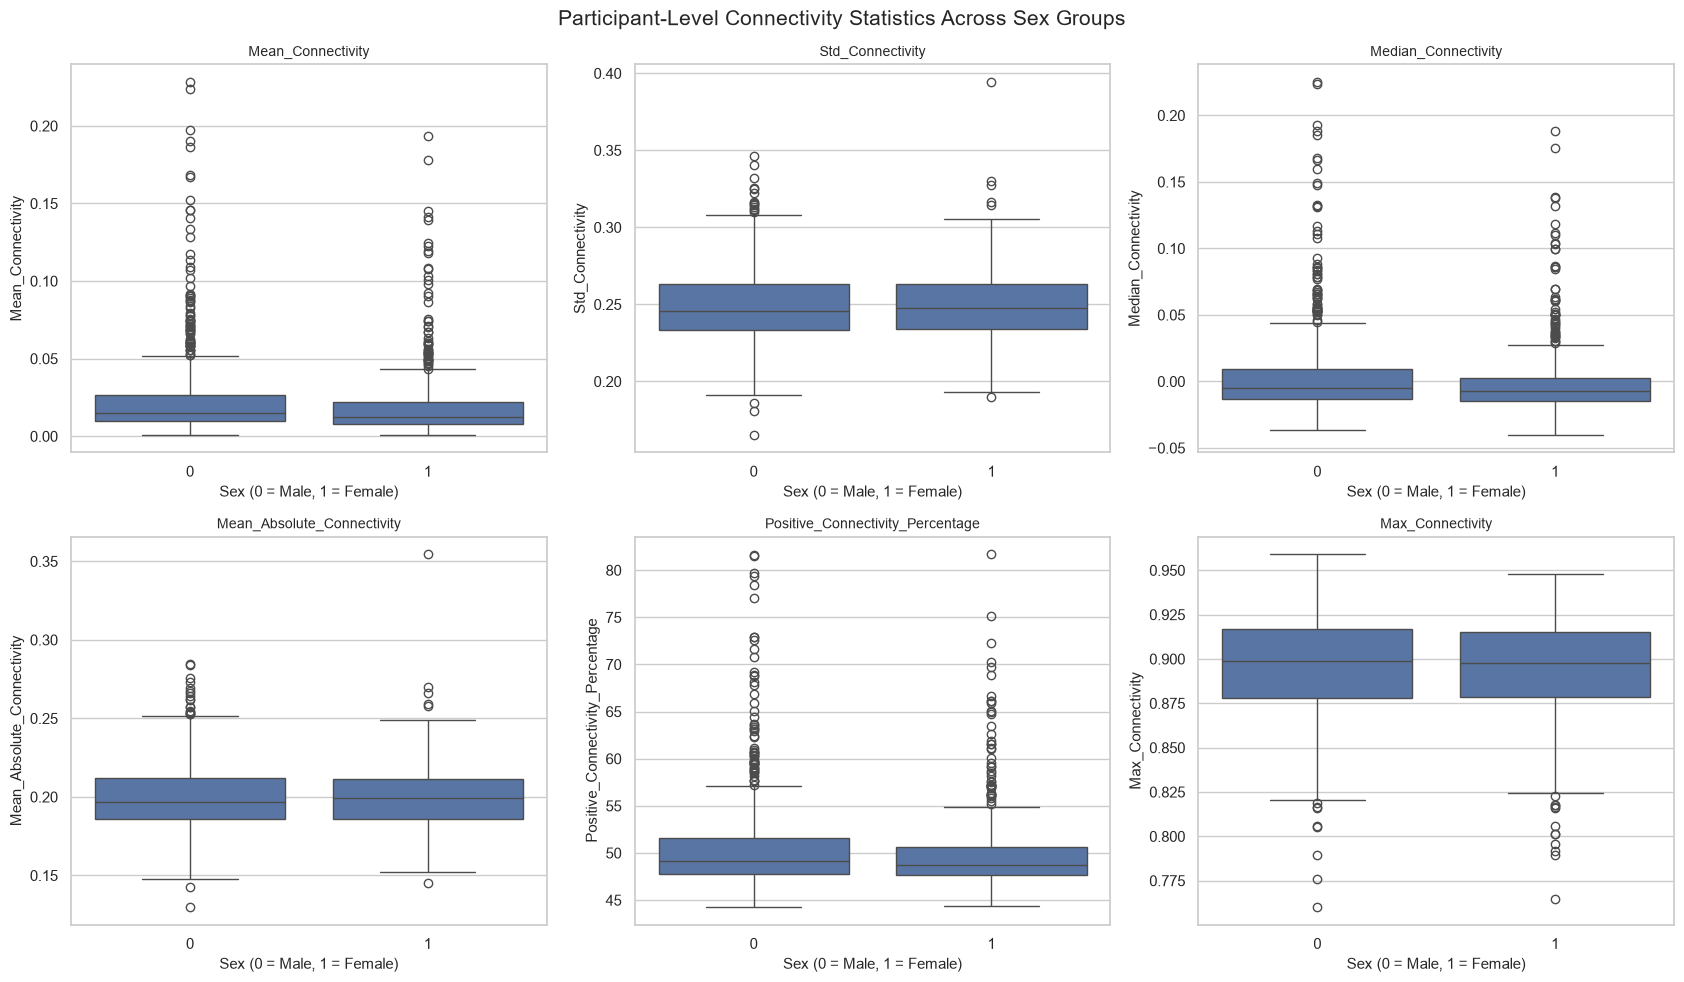

In [80]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, feature in zip(axes.flatten(), summary_features):

    sns.boxplot(
        data=connectome_analysis,
        x="Sex_F",
        y=feature,
        ax=ax
    )

    ax.set_title(feature, fontsize=10)
    ax.set_xlabel("Sex (0 = Male, 1 = Female)")

plt.suptitle(
    "Participant-Level Connectivity Statistics Across Sex Groups",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "20_connectivity_by_sex.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [81]:
group_comparison = (
    connectome_analysis
    .groupby("ADHD_Outcome")[summary_features]
    .agg(["mean", "median", "std"])
)

display(group_comparison.round(4))

Mean_Connectivity              Std_Connectivity               \
                          mean median   std             mean median   std   
ADHD_Outcome                                                                
0                        0.024  0.014 0.030            0.248  0.248 0.025   
1                        0.022  0.014 0.025            0.249  0.247 0.024   

             Median_Connectivity              Mean_Absolute_Connectivity  \
                            mean median   std                       mean   
ADHD_Outcome                                                               
0                          0.004 -0.006 0.035                      0.200   
1                          0.002 -0.006 0.029                      0.200   

                          Positive_Connectivity_Percentage               \
             median   std                             mean median   std   
ADHD_Outcome                                                              
0             0.199 0.022                           50.679 49.048 5.554   
1             0.198 0.021                           50.322 48.965 4.455   

             Max_Connectivity               
                         mean median   std  
ADHD_Outcome                                
0                       0.894  0.898 0.030  
1                       0.896  0.899 0.027


### 7.4 Connectivity Characteristics Across Target Groups

Participant-level connectivity statistics were compared across ADHD outcome and sex groups using boxplots and descriptive statistics.

#### ADHD Outcome Comparison

The following observations were made:

1. Mean connectivity was slightly higher in the non-ADHD group (0.024) compared with the ADHD group (0.022).
2. Standard deviation was almost identical across both groups (0.248 and 0.249).
3. Median connectivity was similar (0.004 and 0.002).
4. Mean absolute connectivity was approximately 0.200 in both groups.
5. Positive connectivity percentage was slightly higher in the non-ADHD group (50.679%) compared with the ADHD group (50.322%).
6. Maximum connectivity was nearly identical across groups.

The boxplots showed substantial overlap between the two groups, suggesting limited separation based on global connectivity summaries.

#### Sex Group Comparison

The participant-level connectivity distributions were also compared between male and female participants.

The distributions showed substantial overlap across the examined summary statistics, with no obvious large differences in overall connectivity characteristics.

#### Key Finding

Global connectivity summaries alone do not visually distinguish ADHD and non-ADHD participants effectively.

However, this does not establish that individual functional connectivity features lack predictive information.

Different participants may have similar global connectivity statistics while exhibiting substantially different connectivity patterns across specific brain-region pairs.

#### Conclusion

Further investigation of individual connectivity features is necessary to identify potentially informative brain-region connections.

These exploratory observations do not establish statistical significance or causal relationships.


In [83]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

def compare_groups(data, group_col, features):

    results = []

    for feature in features:

        group_0 = data.loc[
            data[group_col] == 0, feature
        ].dropna()

        group_1 = data.loc[
            data[group_col] == 1, feature
        ].dropna()

        statistic, p_value = mannwhitneyu(
            group_0,
            group_1,
            alternative="two-sided"
        )

        # Rank-biserial correlation
        effect_size = (
            2 * statistic /
            (len(group_0) * len(group_1))
        ) - 1

        results.append({
            "Feature": feature,
            "Group_0_Median": group_0.median(),
            "Group_1_Median": group_1.median(),
            "U_Statistic": statistic,
            "P_Value": p_value,
            "Rank_Biserial": effect_size
        })

    results = pd.DataFrame(results)

    results["Adjusted_P_Value"] = multipletests(
        results["P_Value"],
        method="fdr_bh"
    )[1]

    results["Significant"] = (
        results["Adjusted_P_Value"] < 0.05
    )

    return results.sort_values("Adjusted_P_Value")

In [84]:
adhd_comparison = compare_groups(
    connectome_analysis,
    "ADHD_Outcome",
    summary_features
)

display(adhd_comparison.round(5))

,Feature,Group_0_Median,Group_1_Median,U_Statistic,P_Value,Rank_Biserial,Adjusted_P_Value,Significant
0,Mean_Connectivity,0.014,0.014,156758.000,0.729,-0.012,0.989,False
1,Std_Connectivity,0.248,0.247,159211.000,0.931,0.003,0.989,False
2,Median_Connectivity,-0.006,-0.006,158639.000,0.989,-0.001,0.989,False
3,Mean_Absolute_Connectivity,0.199,0.197,162892.000,0.462,0.026,0.989,False
4,Positive_Connectivity_Percentage,49.048,48.965,158237.000,0.932,-0.003,0.989,False
5,Max_Connectivity,0.898,0.899,156098.000,0.644,-0.017,0.989,False


In [85]:
sex_comparison = compare_groups(
    connectome_analysis,
    "Sex_F",
    summary_features
)

display(sex_comparison.round(5))

,Feature,Group_0_Median,Group_1_Median,U_Statistic,P_Value,Rank_Biserial,Adjusted_P_Value,Significant
0,Mean_Connectivity,0.015,0.012,187680.000,0.000,0.132,0.001,True
2,Median_Connectivity,-0.005,-0.007,180930.000,0.009,0.091,0.018,True
4,Positive_Connectivity_Percentage,49.141,48.756,181682.500,0.006,0.096,0.018,True
1,Std_Connectivity,0.246,0.248,161544.000,0.465,-0.026,0.601,False
3,Mean_Absolute_Connectivity,0.197,0.200,162544.000,0.577,-0.019,0.601,False
5,Max_Connectivity,0.899,0.897,168804.000,0.601,0.018,0.601,False



### 7.5 Statistical Comparison of Connectivity Summary Features

The Mann–Whitney U test was applied to compare participant-level connectivity statistics across ADHD outcome and sex groups.

Benjamini–Hochberg correction was applied separately to the six tests within each group comparison to control the false discovery rate.

Rank-biserial correlation was calculated to assess the magnitude and direction of group differences.

#### ADHD Outcome Comparison

None of the six connectivity summary features showed statistically significant differences between ADHD and non-ADHD groups after multiple-testing correction.

All adjusted p-values were 0.989, and the rank-biserial correlations were close to zero.

This suggests that the examined global connectivity summaries provide limited separation between ADHD outcome groups.

#### Sex Group Comparison

Three features showed statistically significant differences after multiple-testing correction:

| Feature | Adjusted p-value | Rank-biserial correlation |
|---|---:|---:|
| Mean Connectivity | 0.001 | 0.132 |
| Median Connectivity | 0.018 | 0.091 |
| Positive Connectivity Percentage | 0.018 | 0.096 |

Male participants showed slightly higher median values for these three features.

However, the effect sizes were relatively small, indicating limited differences in practical magnitude.

#### Key Findings

1. No statistically significant differences were detected in the six global connectivity summaries across ADHD outcome groups.
2. Three global connectivity summaries showed small but statistically significant differences across sex groups.
3. Statistical significance should not be confused with practical significance.
4. These comparisons do not establish independent effects after controlling for other participant characteristics.

#### Conclusion

Global connectivity summary features alone do not appear to provide strong discrimination between ADHD outcome groups.

Further investigation of individual connectivity features is necessary to identify potentially informative brain-region connections.


In [86]:
connectome_feature_stats = pd.DataFrame({
    "Mean": train_connectome[connectome_features].mean(),
    "Std": train_connectome[connectome_features].std(),
    "Variance": train_connectome[connectome_features].var(),
    "Min": train_connectome[connectome_features].min(),
    "Max": train_connectome[connectome_features].max()
})

connectome_feature_stats.index.name = "Feature"

display(
    connectome_feature_stats.describe().round(5)
)

,Mean,Std,Variance,Min,Max
count,19900.000,19900.000,19900.000,19900.000,19900.000
mean,0.023,0.189,0.036,-0.563,0.640
std,0.165,0.021,0.008,0.115,0.134
min,-0.363,0.080,0.006,-0.875,0.231
25%,-0.091,0.174,0.030,-0.639,0.537
50%,-0.014,0.185,0.034,-0.579,0.631
75%,0.103,0.201,0.040,-0.508,0.744
max,0.859,0.351,0.124,0.376,0.959


In [87]:
constant_features = connectome_feature_stats[
    connectome_feature_stats["Variance"] == 0
]

low_variance_features = connectome_feature_stats[
    connectome_feature_stats["Variance"] < 0.001
]

print("Total connectivity features:", len(connectome_features))

print("Constant features:", len(constant_features))

print("Low variance features (<0.001):",
      len(low_variance_features))

print("\nLowest variance features:")

display(
    connectome_feature_stats
    .sort_values("Variance")
    .head(20)
    .round(5)
)

Total connectivity features: 19900
Constant features: 0
Low variance features (<0.001): 0

Lowest variance features:


,Mean,Std,Variance,Min,Max
Feature,,,,,
26throw_129thcolumn,0.859,0.080,0.006,0.010,0.956
96throw_194thcolumn,0.786,0.081,0.007,0.209,0.916
9throw_108thcolumn,0.799,0.090,0.008,0.194,0.947
76throw_185thcolumn,0.738,0.095,0.009,0.376,0.918
81throw_186thcolumn,0.739,0.102,0.010,0.230,0.936
44throw_146thcolumn,0.723,0.103,0.011,0.034,0.907
71throw_180thcolumn,0.750,0.104,0.011,0.023,0.930
49throw_155thcolumn,0.687,0.113,0.013,0.142,0.916
0throw_100thcolumn,0.722,0.114,0.013,-0.041,0.924


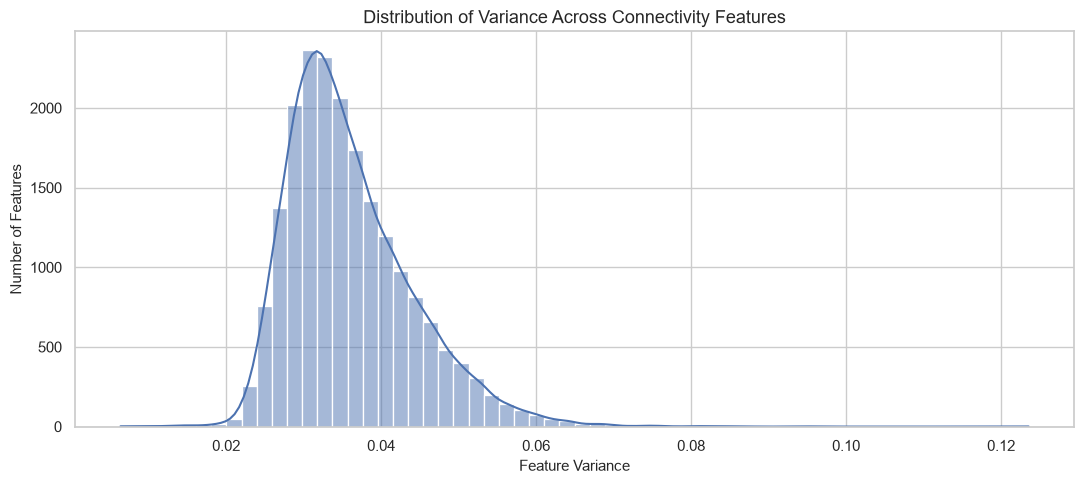

In [88]:
plt.figure(figsize=(11, 5))

sns.histplot(
    connectome_feature_stats["Variance"],
    bins=60,
    kde=True
)

plt.title("Distribution of Variance Across Connectivity Features")
plt.xlabel("Feature Variance")
plt.ylabel("Number of Features")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "21_connectome_feature_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [89]:
top_variance = (
    connectome_feature_stats
    .sort_values("Variance", ascending=False)
    .head(20)
)

bottom_variance = (
    connectome_feature_stats
    .sort_values("Variance")
    .head(20)
)

print("TOP 20 HIGH-VARIANCE CONNECTIONS")

display(top_variance.round(5))

print("\nTOP 20 LOW-VARIANCE CONNECTIONS")

display(bottom_variance.round(5))

TOP 20 HIGH-VARIANCE CONNECTIONS


,Mean,Std,Variance,Min,Max
Feature,,,,,
159throw_177thcolumn,0.358,0.351,0.124,-0.774,0.945
80throw_177thcolumn,0.180,0.321,0.103,-0.736,0.914
70throw_80thcolumn,0.354,0.309,0.096,-0.687,0.921
70throw_159thcolumn,0.222,0.307,0.094,-0.776,0.908
80throw_151thcolumn,-0.096,0.295,0.087,-0.850,0.892
87throw_151thcolumn,-0.118,0.293,0.086,-0.716,0.877
80throw_81thcolumn,0.288,0.291,0.085,-0.709,0.837
159throw_186thcolumn,0.157,0.288,0.083,-0.772,0.830
151throw_188thcolumn,0.054,0.288,0.083,-0.650,0.917



TOP 20 LOW-VARIANCE CONNECTIONS


,Mean,Std,Variance,Min,Max
Feature,,,,,
26throw_129thcolumn,0.859,0.080,0.006,0.010,0.956
96throw_194thcolumn,0.786,0.081,0.007,0.209,0.916
9throw_108thcolumn,0.799,0.090,0.008,0.194,0.947
76throw_185thcolumn,0.738,0.095,0.009,0.376,0.918
81throw_186thcolumn,0.739,0.102,0.010,0.230,0.936
44throw_146thcolumn,0.723,0.103,0.011,0.034,0.907
71throw_180thcolumn,0.750,0.104,0.011,0.023,0.930
49throw_155thcolumn,0.687,0.113,0.013,0.142,0.916
0throw_100thcolumn,0.722,0.114,0.013,-0.041,0.924


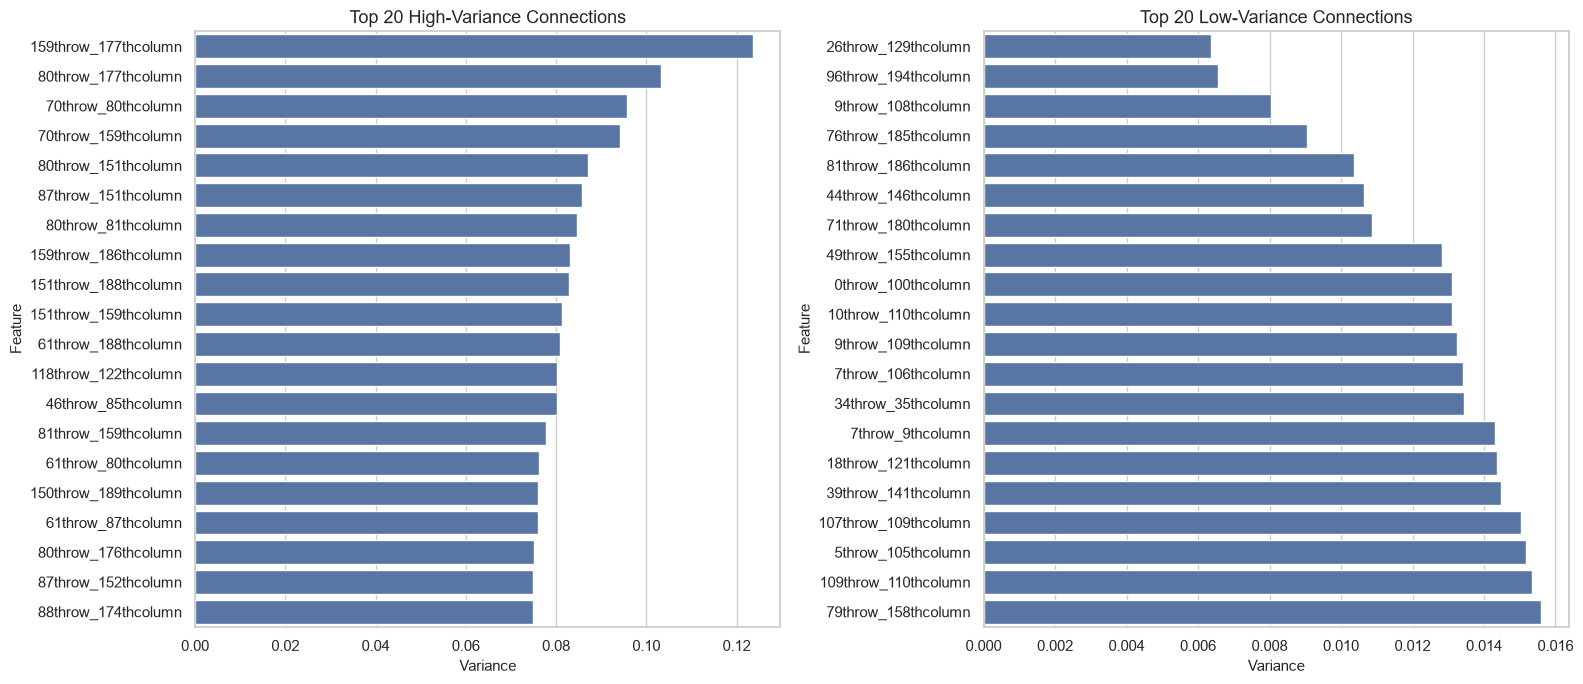

In [90]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=top_variance.reset_index(),
    x="Variance",
    y="Feature",
    ax=axes[0]
)

axes[0].set_title("Top 20 High-Variance Connections")

sns.barplot(
    data=bottom_variance.reset_index(),
    x="Variance",
    y="Feature",
    ax=axes[1]
)

axes[1].set_title("Top 20 Low-Variance Connections")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "22_connectome_variance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 7.6 Individual Connectivity Feature Variability

Feature-level descriptive statistics were calculated across all 19,900 functional connectivity features using the 1,213 training participants.

#### Overall Variability

- Mean feature variance: 0.036
- Median feature variance: 0.034
- Minimum feature variance: 0.006
- Maximum feature variance: 0.124
- Mean feature standard deviation: 0.189

The distribution of feature variances is positively skewed, with most features exhibiting moderate variability and a smaller number exhibiting relatively high variability.

#### Constant and Low-Variance Features

- Total connectivity features: 19,900
- Constant features: 0
- Features with variance below 0.001: 0

Every connectivity feature exhibits non-zero variation across participants.

Consequently, no features were removed based on constant or low variance at this stage.

#### High-Variance Connections

The highest-variance connection was between regions 159 and 177, with a variance of approximately 0.124.

Other high-variance connections included 80–177, 70–80, 70–159 and 80–151.

These connections exhibit relatively large variation in connectivity measurements across participants.

#### Low-Variance Connections

The lowest-variance connection was between regions 26 and 129, with a variance of approximately 0.006.

Interestingly, several low-variance connections exhibited high positive mean connectivity values.

This demonstrates that average connectivity strength and connectivity variability represent different properties.

#### Conclusion

All 19,900 connectivity features exhibit non-zero variation.

However, variance alone does not establish predictive relevance for ADHD classification.

No connectivity features were eliminated based on variance during this exploratory analysis.


In [93]:
rng = np.random.default_rng(42)

sampled_connectome_features = rng.choice(
    connectome_features,
    size=500,
    replace=False
).tolist()

sampled_connectome = train_connectome[
    sampled_connectome_features
]

print("Original feature count:", len(connectome_features))
print("Sampled feature count:", len(sampled_connectome_features))
print("Sample shape:", sampled_connectome.shape)

Original feature count: 19900
Sampled feature count: 500
Sample shape: (1213, 500)


In [94]:
connectome_corr = sampled_connectome.corr(
    method="pearson"
)

display(connectome_corr.iloc[:10, :10].round(2))

,46throw_190thcolumn,137throw_166thcolumn,40throw_121thcolumn,11throw_185thcolumn,45throw_86thcolumn,30throw_120thcolumn,71throw_132thcolumn,96throw_174thcolumn,121throw_144thcolumn,139throw_183thcolumn
46throw_190thcolumn,1.000,0.060,0.000,0.070,0.010,-0.020,0.030,0.080,-0.010,0.050
137throw_166thcolumn,0.060,1.000,-0.030,0.060,-0.050,-0.020,-0.000,0.110,-0.040,-0.030
40throw_121thcolumn,0.000,-0.030,1.000,0.090,0.060,-0.030,0.040,-0.010,0.580,0.010
11throw_185thcolumn,0.070,0.060,0.090,1.000,0.050,0.010,0.120,-0.030,0.060,0.110
45throw_86thcolumn,0.010,-0.050,0.060,0.050,1.000,0.060,0.120,0.050,0.020,0.210
30throw_120thcolumn,-0.020,-0.020,-0.030,0.010,0.060,1.000,0.010,-0.000,0.020,-0.010
71throw_132thcolumn,0.030,-0.000,0.040,0.120,0.120,0.010,1.000,0.040,-0.020,0.110
96throw_174thcolumn,0.080,0.110,-0.010,-0.030,0.050,-0.000,0.040,1.000,0.010,0.080
121throw_144thcolumn,-0.010,-0.040,0.580,0.060,0.020,0.020,-0.020,0.010,1.000,-0.030
139throw_183thcolumn,0.050,-0.030,0.010,0.110,0.210,-0.010,0.110,0.080,-0.030,1.000


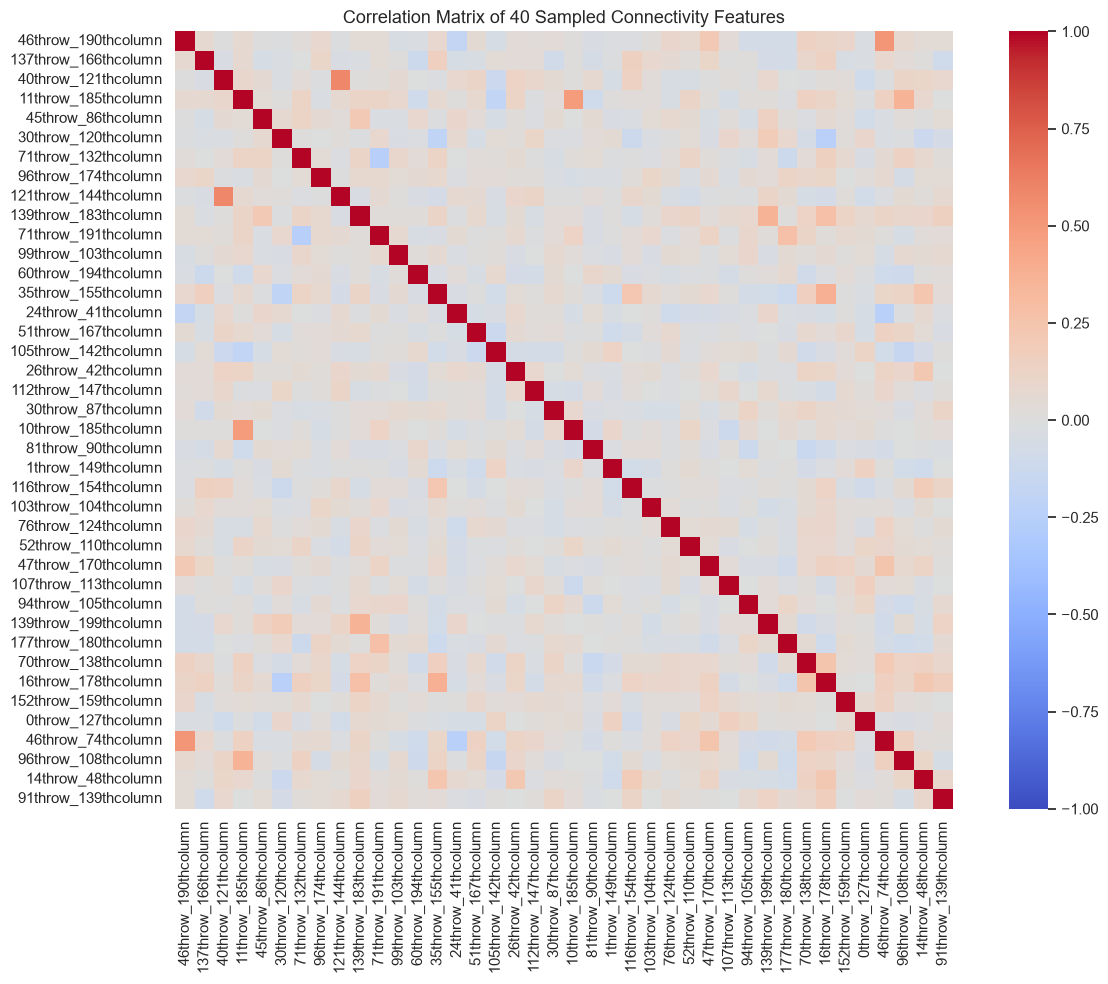

In [95]:
plt.figure(figsize=(13, 10))

sns.heatmap(
    connectome_corr.iloc[:40, :40],
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    xticklabels=True,
    yticklabels=True
)

plt.title(
    "Correlation Matrix of 40 Sampled Connectivity Features"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "23_connectome_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [101]:
upper_triangle = np.triu(
    np.ones(connectome_corr.shape),
    k=1
).astype(bool)

correlation_pairs = (
    connectome_corr
    .where(upper_triangle)
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Feature_1",
    "Feature_2",
    "Correlation"
]

correlation_pairs["Absolute_Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

highly_correlated_pairs = (
    correlation_pairs[
        correlation_pairs["Absolute_Correlation"] >= 0.80
    ]
    .sort_values(
        "Absolute_Correlation",
        ascending=False
    )
)

print(
    "Total feature pairs examined:",
    len(correlation_pairs)
)

print(
    "Pairs with |correlation| >= 0.80:",
    len(highly_correlated_pairs)
)

display(highly_correlated_pairs.head(20).round(4))

Total feature pairs examined: 250000
Pairs with |correlation| >= 0.80: 1


,Feature_1,Feature_2,Correlation,Absolute_Correlation
88260,136throw_185thcolumn,76throw_136thcolumn,0.853,0.853


,Pair_Count
Absolute_Correlation,
Weak (0–0.3),124118
Moderate (0.3–0.5),558
Strong (0.5–0.7),68
Very Strong (0.7–0.9),6
Extremely Strong (0.9–1.0),0


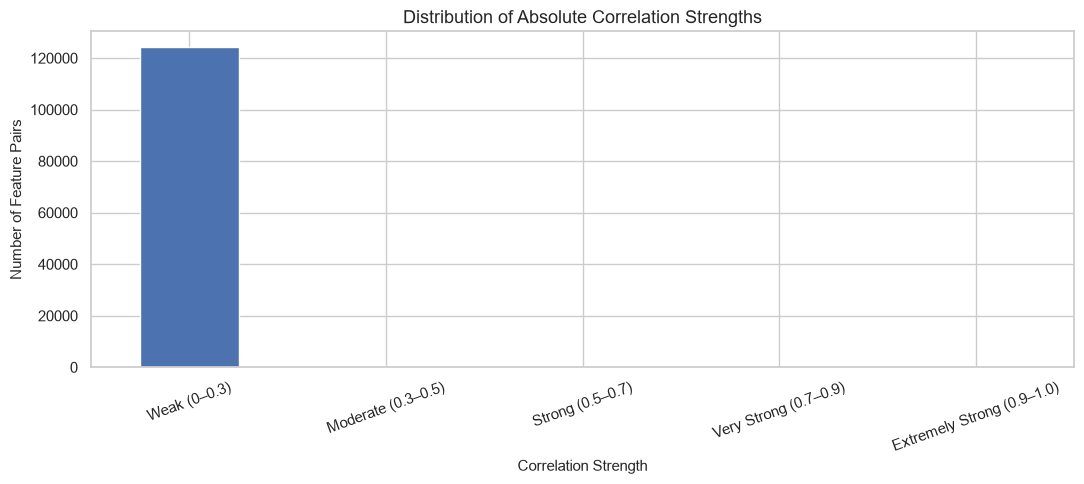

In [99]:
correlation_strength = pd.cut(
    correlation_pairs["Absolute_Correlation"],
    bins=[0, 0.3, 0.5, 0.7, 0.9, 1.0],
    labels=[
        "Weak (0–0.3)",
        "Moderate (0.3–0.5)",
        "Strong (0.5–0.7)",
        "Very Strong (0.7–0.9)",
        "Extremely Strong (0.9–1.0)"
    ],
    include_lowest=True
)

correlation_distribution = (
    correlation_strength
    .value_counts()
    .sort_index()
)

display(
    correlation_distribution.to_frame("Pair_Count")
)

plt.figure(figsize=(11, 5))

correlation_distribution.plot(
    kind="bar",
    rot=20
)

plt.title(
    "Distribution of Absolute Correlation Strengths"
)

plt.xlabel("Correlation Strength")
plt.ylabel("Number of Feature Pairs")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "24_connectome_correlation_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 7.7 Connectivity Feature Correlation and Redundancy

Pearson correlation analysis was performed on a reproducible random sample of 500 connectivity features to investigate linear relationships and potential redundancy.

A complete correlation matrix of all 19,900 features was avoided due to its substantial memory requirements.

#### Correlation Structure

The sampled correlation matrix showed predominantly weak pairwise linear relationships.

Among the 124,750 unique feature pairs:

- Weak correlations (|r| < 0.3): 124,118
- Moderate correlations (0.3–0.5): 558
- Strong correlations (0.5–0.7): 68
- Very strong correlations (0.7–0.9): 6
- Extremely strong correlations (0.9–1.0): 0

#### Highly Correlated Connections

Using an absolute correlation threshold of 0.80, one highly correlated pair was identified:

- Connection 136–185
- Connection 76–136
- Pearson correlation: 0.853

Both connections involve brain region 136, suggesting a potentially interesting relationship for further investigation.

#### Key Findings

1. Most sampled connectivity feature pairs exhibit weak linear correlations.
2. Only a small proportion of pairs exhibit strong or very strong correlations.
3. One pair exhibited an absolute correlation greater than or equal to 0.80.
4. No pairs exhibited an absolute correlation greater than or equal to 0.90.

#### Conclusion

The sampled connectivity features exhibit relatively low pairwise linear redundancy.

However, this analysis covers only 500 randomly selected features and cannot establish the correlation structure of all 19,900 features.

Further feature selection should consider predictive relevance, redundancy and model performance rather than relying exclusively on pairwise correlations.


In [102]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# Separate participants by ADHD outcome

adhd_0_ids = connectome_analysis.loc[
    connectome_analysis["ADHD_Outcome"] == 0,
    "participant_id"
]

adhd_1_ids = connectome_analysis.loc[
    connectome_analysis["ADHD_Outcome"] == 1,
    "participant_id"
]

# Preserve the same feature ordering

X_adhd_0 = (
    train_connectome
    .set_index("participant_id")
    .loc[adhd_0_ids, connectome_features]
    .to_numpy()
)

X_adhd_1 = (
    train_connectome
    .set_index("participant_id")
    .loc[adhd_1_ids, connectome_features]
    .to_numpy()
)

print("No ADHD:", X_adhd_0.shape)
print("ADHD:", X_adhd_1.shape)

print("Total features:", X_adhd_0.shape[1])

No ADHD: (382, 19900)
ADHD: (831, 19900)
Total features: 19900


In [103]:
u_statistics, p_values = mannwhitneyu(
    X_adhd_0,
    X_adhd_1,
    axis=0,
    alternative="two-sided",
    method="asymptotic"
)

# Rank-biserial correlation

rank_biserial = (
    2 * u_statistics /
    (X_adhd_0.shape[0] * X_adhd_1.shape[0])
) - 1

# Benjamini-Hochberg correction

rejected, adjusted_p_values, _, _ = multipletests(
    p_values,
    method="fdr_bh"
)

adhd_connectivity_results = pd.DataFrame({
    "Feature": connectome_features,
    "U_Statistic": u_statistics,
    "P_Value": p_values,
    "Adjusted_P_Value": adjusted_p_values,
    "Rank_Biserial": rank_biserial,
    "Significant": rejected
})

print("Total tests:", len(adhd_connectivity_results))

print("Significant connections:",
      rejected.sum())

print("Significant connections after FDR:",
      (adjusted_p_values < 0.05).sum())

Total tests: 19900
Significant connections: 0
Significant connections after FDR: 0


In [104]:
adhd_connectivity_results = (
    adhd_connectivity_results
    .sort_values("Adjusted_P_Value")
    .reset_index(drop=True)
)

print("TOP 20 CONNECTIONS BY ADJUSTED P-VALUE")

display(
    adhd_connectivity_results.head(20).round(6)
)

TOP 20 CONNECTIONS BY ADJUSTED P-VALUE


,Feature,U_Statistic,P_Value,Adjusted_P_Value,Rank_Biserial,Significant
0,1throw_16thcolumn,184923.000,0.000,0.075,0.165,False
1,78throw_170thcolumn,183394.000,0.000,0.095,0.155,False
2,2throw_166thcolumn,183205.000,0.000,0.095,0.154,False
3,166throw_184thcolumn,134488.000,0.000,0.095,-0.153,False
4,78throw_189thcolumn,181983.000,0.000,0.161,0.147,False
5,76throw_170thcolumn,181706.000,0.000,0.165,0.145,False
6,159throw_166thcolumn,136111.000,0.000,0.165,-0.142,False
7,11throw_166thcolumn,181424.000,0.000,0.165,0.143,False
8,50throw_189thcolumn,180394.500,0.000,0.204,0.137,False
9,96throw_169thcolumn,137039.000,0.000,0.204,-0.137,False


In [105]:
adhd_group_means = pd.DataFrame({
    "Feature": connectome_features,

    "No_ADHD_Mean": X_adhd_0.mean(axis=0),

    "ADHD_Mean": X_adhd_1.mean(axis=0),

    "No_ADHD_Median": np.median(X_adhd_0, axis=0),

    "ADHD_Median": np.median(X_adhd_1, axis=0)
})

adhd_group_means["Mean_Difference"] = (
    adhd_group_means["ADHD_Mean"]
    - adhd_group_means["No_ADHD_Mean"]
)

adhd_connectivity_results = (
    adhd_connectivity_results
    .merge(
        adhd_group_means,
        on="Feature",
        how="left",
        validate="one_to_one"
    )
)

display(
    adhd_connectivity_results.head(20).round(5)
)

,Feature,U_Statistic,P_Value,Adjusted_P_Value,Rank_Biserial,Significant,No_ADHD_Mean,ADHD_Mean,No_ADHD_Median,ADHD_Median,Mean_Difference
0,1throw_16thcolumn,184923.000,0.000,0.075,0.165,False,-0.052,-0.101,-0.041,-0.104,-0.049
1,78throw_170thcolumn,183394.000,0.000,0.095,0.155,False,0.247,0.191,0.271,0.212,-0.056
2,2throw_166thcolumn,183205.000,0.000,0.095,0.154,False,-0.025,-0.070,-0.029,-0.076,-0.045
3,166throw_184thcolumn,134488.000,0.000,0.095,-0.153,False,0.312,0.374,0.345,0.405,0.063
4,78throw_189thcolumn,181983.000,0.000,0.161,0.147,False,0.231,0.181,0.241,0.188,-0.050
5,76throw_170thcolumn,181706.000,0.000,0.165,0.145,False,0.397,0.354,0.406,0.364,-0.043
6,159throw_166thcolumn,136111.000,0.000,0.165,-0.142,False,-0.017,0.030,-0.018,0.026,0.047
7,11throw_166thcolumn,181424.000,0.000,0.165,0.143,False,-0.014,-0.063,-0.007,-0.070,-0.049
8,50throw_189thcolumn,180394.500,0.000,0.204,0.137,False,0.036,-0.006,0.035,-0.005,-0.042
9,96throw_169thcolumn,137039.000,0.000,0.204,-0.137,False,0.050,0.084,0.053,0.094,0.034


In [106]:
print("Sampled features:", len(sampled_connectome_features))

print("Expected unique pairs:",
      len(sampled_connectome_features) *
      (len(sampled_connectome_features) - 1) // 2)

print("Actual correlation pairs:", len(correlation_pairs))

print("Sum of correlation categories:",
      correlation_distribution.sum())

Sampled features: 500
Expected unique pairs: 124750
Actual correlation pairs: 250000
Sum of correlation categories: 124750


In [107]:
# Extract only the upper triangle, excluding the diagonal

row_idx, col_idx = np.triu_indices(
    len(connectome_corr),
    k=1
)

correlation_pairs = pd.DataFrame({
    "Feature_1": connectome_corr.columns[row_idx],
    "Feature_2": connectome_corr.columns[col_idx],
    "Correlation": connectome_corr.to_numpy()[row_idx, col_idx]
})

correlation_pairs["Absolute_Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

print("Actual unique pairs:", len(correlation_pairs))
print("Expected unique pairs:", 500 * 499 // 2)

Actual unique pairs: 124750
Expected unique pairs: 124750


In [108]:
print("Raw p-value < 0.05:",
      (adhd_connectivity_results["P_Value"] < 0.05).sum())

print("Raw p-value < 0.01:",
      (adhd_connectivity_results["P_Value"] < 0.01).sum())

print("FDR-adjusted p-value < 0.05:",
      (adhd_connectivity_results["Adjusted_P_Value"] < 0.05).sum())

print("\nSmallest raw p-values:")

display(
    adhd_connectivity_results[
        ["Feature", "P_Value", "Adjusted_P_Value"]
    ].head(10).to_string(index=False)
)

Raw p-value < 0.05: 1345
Raw p-value < 0.01: 371
FDR-adjusted p-value < 0.05: 0

Smallest raw p-values:


'             Feature  P_Value  Adjusted_P_Value\n   1throw_16thcolumn    0.000             0.075\n 78throw_170thcolumn    0.000             0.095\n  2throw_166thcolumn    0.000             0.095\n166throw_184thcolumn    0.000             0.095\n 78throw_189thcolumn    0.000             0.161\n 76throw_170thcolumn    0.000             0.165\n159throw_166thcolumn    0.000             0.165\n 11throw_166thcolumn    0.000             0.165\n 50throw_189thcolumn    0.000             0.204\n 96throw_169thcolumn    0.000             0.204'

In [109]:
adhd_connectivity_results.to_csv(
    OUTPUT_DIR / "adhd_connectivity_statistical_tests.csv",
    index=False
)

print("Statistical results saved successfully.")

Statistical results saved successfully.



### 7.8 Individual Connectivity Differences Across ADHD Groups

Individual connectivity features were compared between ADHD and non-ADHD participants using the Mann–Whitney U test.

The analysis included:

- Non-ADHD participants: 382
- ADHD participants: 831
- Total connectivity features tested: 19,900

#### Statistical Methodology

A two-sided Mann–Whitney U test was conducted independently for each connectivity feature.

The Benjamini–Hochberg procedure was applied to adjust p-values for multiple hypothesis testing, controlling the false discovery rate at 5%.

Rank-biserial correlation was also calculated to estimate the magnitude and direction of group differences.

#### Results

- Total statistical tests: 19,900
- Minimum adjusted p-value: 0.075
- Features significant after FDR correction: 0

Although several connections exhibited small raw p-values, none remained statistically significant after multiple-testing correction.

#### Top Observed Connections

The most promising uncorrected connections included:

- 1–16
- 78–170
- 2–166
- 166–184
- 78–189

The corresponding rank-biserial correlations ranged approximately from -0.153 to 0.165 among the top 20 connections.

These results indicate some distributional differences between the groups, but the findings do not provide sufficient statistical evidence to establish individual connectivity differences after FDR correction.

#### Interpretation

The absence of FDR-significant connections does not establish the absence of ADHD-related functional connectivity patterns.

Potential explanations include:

1. High dimensionality and multiple-testing penalties.
2. Relatively small individual feature effect sizes.
3. Complex relationships involving combinations of connectivity features rather than isolated connections.
4. Potential confounding variables such as sex and age.

#### Conclusion

No individual connectivity feature demonstrated statistically significant differences between ADHD and non-ADHD groups after FDR correction.

Therefore, individual univariate significance alone is unlikely to be sufficient for identifying useful predictive connectivity features.

Multivariate modelling and feature selection will be investigated in subsequent stages.


In [110]:
pd.set_option("display.float_format", lambda x: f"{x:.3e}")

display(
    adhd_connectivity_results[
        ["Feature", "P_Value", "Adjusted_P_Value"]
    ].head(10)
)

pd.reset_option("display.float_format")

,Feature,P_Value,Adjusted_P_Value
0,1throw_16thcolumn,3.772e-06,7.507e-02
1,78throw_170thcolumn,1.338e-05,9.462e-02
2,2throw_166thcolumn,1.558e-05,9.462e-02
3,166throw_184thcolumn,1.902e-05,9.462e-02
4,78throw_189thcolumn,4.048e-05,1.611e-01
5,76throw_170thcolumn,4.995e-05,1.646e-01
6,159throw_166thcolumn,6.616e-05,1.646e-01
7,11throw_166thcolumn,6.173e-05,1.646e-01
8,50throw_189thcolumn,1.311e-04,2.037e-01
9,96throw_169thcolumn,1.303e-04,2.037e-01



#### Statistical Results

A total of 19,900 individual connectivity features were tested.

Before multiple-testing correction:

- 1,345 features had raw p-values below 0.05.
- 371 features had raw p-values below 0.01.

After applying Benjamini–Hochberg FDR correction:

- No features remained significant at an adjusted p-value threshold of 0.05.
- The minimum adjusted p-value was 0.075.

#### Interpretation

Although several connectivity features exhibited nominally significant differences between ADHD and non-ADHD groups, none survived multiple-testing correction.

This highlights the importance of controlling the false discovery rate when performing high-dimensional statistical analyses.

The results suggest that isolated connectivity features may have relatively modest group differences, and that potentially informative patterns could involve combinations of multiple connections.

No individual connectivity feature was established as statistically significant after FDR correction.



## 8. Functional Connectome EDA — Overall Conclusions

The functional connectome dataset contains 19,900 pairwise Pearson correlation features representing connectivity between 200 brain regions for each participant.

The exploratory analysis produced the following findings.

### 8.1 Data Integrity

- Training participants: 1,213
- Connectivity features: 19,900
- Unique brain regions: 200
- All connections represent unique region pairs.
- No duplicate participant IDs were identified.
- No missing or infinite connectivity values were found.
- Training and testing feature columns are consistent.

### 8.2 Connectivity Distributions

Connectivity values contain both positive and negative correlations, with an overall mean close to zero.

The distribution is approximately unimodal with some asymmetry.

Participant-level connectivity statistics revealed variation across individuals, although aggregate statistics showed limited separation between ADHD groups.

### 8.3 Participant-Level Comparisons

The six investigated connectivity summary statistics did not show statistically significant ADHD-group differences after FDR correction.

Sex comparisons showed statistically significant differences in some participant-level connectivity statistics.

This indicates that demographic variables may be relevant when investigating connectivity patterns.

### 8.4 Feature Variability

All 19,900 connectivity features exhibited non-zero variance.

No constant or near-zero-variance features were identified using the variance threshold of 0.001.

Connectivity features showed substantial variation in their individual distributions.

### 8.5 Feature Correlation and Redundancy

A random sample of 500 connectivity features was used to investigate pairwise Pearson correlations.

Most sampled feature pairs exhibited weak linear correlations.

Only a small number of pairs exhibited strong or very strong correlations.

One pair demonstrated an absolute correlation of 0.853.

### 8.6 Individual ADHD-Related Connectivity

Mann–Whitney U tests were conducted across all 19,900 connectivity features.

Although 1,345 features exhibited raw p-values below 0.05, none remained significant after Benjamini–Hochberg FDR correction.

This indicates that no individual connectivity feature demonstrated sufficiently strong evidence of an ADHD-group difference after multiple-testing correction.

### 8.7 Implications for Modelling

The findings suggest several considerations for subsequent modelling:

1. The high dimensionality of the connectome requires appropriate feature selection or dimensionality reduction.
2. Variance-based filtering alone is unlikely to be sufficient.
3. Individual univariate statistical significance may not capture potentially informative multivariate patterns.
4. Demographic variables, particularly sex and age, should be considered during modelling.
5. Feature selection must be performed exclusively within training folds to prevent data leakage.

### Overall Conclusion

The functional connectome dataset is structurally complete and contains substantial variation across participants and connectivity features.

However, exploratory univariate comparisons did not establish statistically significant individual connectivity differences associated with ADHD after multiple-testing correction.

The next stage will investigate appropriate preprocessing, feature engineering, dimensionality reduction and multivariate machine learning approaches to determine whether combinations of connectivity measurements can improve ADHD prediction.


In [1]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("../outputs")

files_to_check = [
    "development_data.csv",
    "holdout_data.csv",
    "train_merged.csv",
    "test_merged.csv"
]

for filename in files_to_check:

    filepath = OUTPUT_DIR / filename

    print("\n" + "=" * 60)
    print(filename)
    print("=" * 60)

    if filepath.exists():

        df_temp = pd.read_csv(filepath)

        print("Shape:", df_temp.shape)
        print("Columns:", len(df_temp.columns))

        if "ADHD_Outcome" in df_temp.columns:
            print("\nTarget distribution:")
            print(df_temp["ADHD_Outcome"].value_counts())

        if "participant_id" in df_temp.columns:
            print("\nUnique participants:",
                  df_temp["participant_id"].nunique())

    else:
        print("File not found!")



development_data.csv
Shape: (970, 19930)
Columns: 19930

Target distribution:
ADHD_Outcome
1    664
0    306
Name: count, dtype: int64

Unique participants: 970

holdout_data.csv
Shape: (243, 19930)
Columns: 19930

Target distribution:
ADHD_Outcome
1    167
0     76
Name: count, dtype: int64

Unique participants: 243

train_merged.csv
Shape: (1213, 19930)
Columns: 19930

Target distribution:
ADHD_Outcome
1    831
0    382
Name: count, dtype: int64

Unique participants: 1213

test_merged.csv
Shape: (304, 19928)
Columns: 19928

Unique participants: 304
